In [1]:

# ============================================================
# RQ1: GEOGRAPHIC DISTRIBUTION ANALYSIS
# STEP 4.1: LOAD AND VALIDATE DATASET
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configure paths
DATA_DIR = Path(r"E:\Analytic Plan BI\LinkedIn Dataset")
OUTPUT_DIR = DATA_DIR / "Assignment_2_Analysis"

# Load our final validated dataset
us_ba_geo = pd.read_csv(
    OUTPUT_DIR / "US_BA_GEOGRAPHY.csv"
)

# Dataset overview
print("=" * 60)
print("RQ1: GEOGRAPHIC DISTRIBUTION ANALYSIS")
print("=" * 60)

print("\nTotal advertisements:", len(us_ba_geo))
print("Unique job links:", us_ba_geo["job_link"].nunique())

print("\nState identification:")
print("Identified:", us_ba_geo["state_clean"].notna().sum())
print("Unidentified:", us_ba_geo["state_clean"].isna().sum())

print("\nNumber of states/jurisdictions represented:")
print(us_ba_geo["state_clean"].nunique())

print("\nTop 10 states:")
display(
    us_ba_geo["state_clean"]
    .value_counts()
    .head(10)
)

# Validation checks
assert len(us_ba_geo) == 3722, "Unexpected dataset size"
assert us_ba_geo["job_link"].is_unique, "Duplicate job links found"

print("\nAll validation checks passed.")


RQ1: GEOGRAPHIC DISTRIBUTION ANALYSIS

Total advertisements: 3722
Unique job links: 3722

State identification:
Identified: 3708
Unidentified: 14

Number of states/jurisdictions represented:
50

Top 10 states:


state_clean
TX    341
CA    339
FL    279
NY    255
NJ    205
VA    180
MA    165
NC    158
GA    157
IL    144
Name: count, dtype: int64


All validation checks passed.


RQ1 - STATE-LEVEL DISTRIBUTION
Total BA advertisements: 3,722
State-identified advertisements: 3,708
Unidentified advertisements: 14
States represented: 50

Top 5 states' share: 38.27%
Top 10 states' share: 59.95%
State concentration HHI: 471.57

Top 15 states:


,State,Advertisements,Share (%),Cumulative Share (%)
0,TX,341,9.20,9.20
1,CA,339,9.14,18.34
2,FL,279,7.52,25.86
3,NY,255,6.88,32.74
4,NJ,205,5.53,38.27
5,VA,180,4.85,43.12
6,MA,165,4.45,47.57
7,NC,158,4.26,51.83
8,GA,157,4.23,56.07
9,IL,144,3.88,59.95


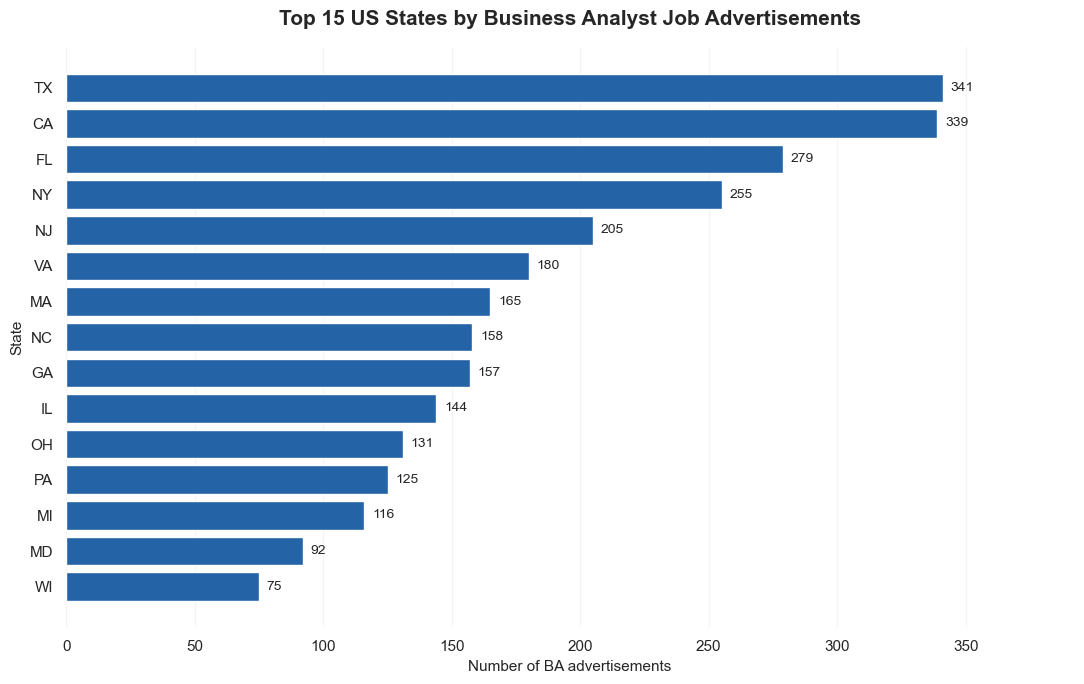


State distribution table and figure saved successfully.


In [2]:

# ============================================================
# RQ1 - STEP 4.2: STATE-LEVEL ADVERTISEMENT DISTRIBUTION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Count advertisements by state
state_counts = (
    us_ba_geo["state_clean"]
    .dropna()
    .value_counts()
    .rename_axis("State")
    .reset_index(name="Advertisements")
)

# 2. Calculate state shares using identified-state records
total_identified = state_counts["Advertisements"].sum()
total_ba = len(us_ba_geo)

state_counts["Share (%)"] = (
    state_counts["Advertisements"] / total_identified * 100
).round(2)

state_counts["Cumulative Share (%)"] = (
    state_counts["Advertisements"].cumsum()
    / total_identified * 100
).round(2)

# 3. Summary measures
top_5_share = (
    state_counts.head(5)["Advertisements"].sum()
    / total_identified * 100
)

top_10_share = (
    state_counts.head(10)["Advertisements"].sum()
    / total_identified * 100
)

state_hhi = (
    (state_counts["Advertisements"] / total_identified) ** 2
).sum() * 10000

print("=" * 65)
print("RQ1 - STATE-LEVEL DISTRIBUTION")
print("=" * 65)

print(f"Total BA advertisements: {total_ba:,}")
print(f"State-identified advertisements: {total_identified:,}")
print(f"Unidentified advertisements: {total_ba - total_identified:,}")
print(f"States represented: {len(state_counts)}")

print(f"\nTop 5 states' share: {top_5_share:.2f}%")
print(f"Top 10 states' share: {top_10_share:.2f}%")
print(f"State concentration HHI: {state_hhi:.2f}")

print("\nTop 15 states:")
display(state_counts.head(15))

# 4. Visualise top 15 states
top_15 = state_counts.head(15).sort_values(
    "Advertisements", ascending=True
)

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    top_15["State"],
    top_15["Advertisements"],
    color="#2463A6",
    edgecolor="white"
)

for bar, value in zip(bars, top_15["Advertisements"]):
    ax.text(
        value + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Top 15 US States by Business Analyst Job Advertisements",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Number of BA advertisements", fontsize=11)
ax.set_ylabel("State", fontsize=11)
ax.set_xlim(0, top_15["Advertisements"].max() * 1.15)

ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)
plt.tight_layout()

# 5. Save results
state_counts.to_csv(
    OUTPUT_DIR / "RQ1_STATE_DISTRIBUTION.csv",
    index=False
)

fig.savefig(
    OUTPUT_DIR / "RQ1_Figure_1_State_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nState distribution table and figure saved successfully.")


In [3]:

# RQ1 - STEP 4.3A: CHECK GEOGRAPHIC CODES

print("All state codes and advertisement counts:")
display(
    state_counts.sort_values("State").reset_index(drop=True)
)

print("\nDistrict of Columbia records:")
display(
    us_ba_geo[
        us_ba_geo["job_location"]
        .astype(str)
        .str.contains(
            r"Washington,\s*DC|District of Columbia",
            case=False,
            regex=True,
            na=False
        )
    ][["job_location", "state_clean"]].value_counts().head(15)
)

print("\nState-unidentified locations:")
display(
    us_ba_geo.loc[
        us_ba_geo["state_clean"].isna(),
        "job_location"
    ].value_counts()
)


All state codes and advertisement counts:


,State,Advertisements,Share (%),Cumulative Share (%)
0,AK,4,0.11,99.57
1,AL,28,0.76,92.56
2,AR,22,0.59,95.28
3,AZ,46,1.24,90.21
4,CA,339,9.14,18.34
5,CO,62,1.67,81.58
6,CT,55,1.48,86.19
7,DC,59,1.59,83.17
8,DE,13,0.35,98.38
9,FL,279,7.52,25.86



District of Columbia records:


job_location                         state_clean
Washington, DC                       DC             55
District of Columbia, United States  DC              3
Name: count, dtype: int64


State-unidentified locations:


job_location
United States    14
Name: count, dtype: int64

In [8]:
bls_raw = pd.read_excel(
    OUTPUT_DIR / "BLS_January_2024_Labour_Force.xlsx",
    header=None
)

display(bls_raw.head(12))

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,State and area,Civilian labor force,NaN,NaN,NaN,Unemployed,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Jan.,Nov.,Dec.,Jan.,Number,NaN,NaN,NaN,Percent of labor force,NaN,NaN,NaN
2,NaN,2023,2023,2023,2024(p),Jan.,Nov.,Dec.,Jan.,Jan.,Nov.,Dec.,Jan.
3,NaN,NaN,NaN,NaN,NaN,2023,2023,2023,2024(p),2023,2023,2023,2024(p)
4,Alabama,2284000,2326130,2325305,2327861,53887,64404,64101,66591,2.4,2.8,2.8,2.9
5,Alaska,353849,358631,358598,358278,13873,16394,16322,16420,3.9,4.6,4.6,4.6
6,Arizona,3640979,3721710,3720507,3726618,136130,157204,156449,155076,3.7,4.2,4.2,4.2
7,Arkansas,1366856,1384466,1384754,1385260,40907,51093,50736,50782,3,3.7,3.7,3.7
8,California,19250558,19325362,19342132,19357440,857765,993488,990259,1013585,4.5,5.1,5.1,5.2
9,Los Angeles-Long Beach-Glendale(1),5023750,4999283,5006096,5007586,249218,263442,262773,269767,5,5.3,5.2,5.4


In [9]:

# ============================================================
# RQ1 - STEP 4.3C: CLEAN AND MERGE BLS LABOUR FORCE DATA
# ============================================================

import pandas as pd
import numpy as np

# 1. State name to abbreviation mapping
state_to_code = {
    "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ",
    "Arkansas": "AR", "California": "CA", "Colorado": "CO",
    "Connecticut": "CT", "Delaware": "DE",
    "District of Columbia": "DC", "Florida": "FL",
    "Georgia": "GA", "Hawaii": "HI", "Idaho": "ID",
    "Illinois": "IL", "Indiana": "IN", "Iowa": "IA",
    "Kansas": "KS", "Kentucky": "KY", "Louisiana": "LA",
    "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA",
    "Michigan": "MI", "Minnesota": "MN",
    "Mississippi": "MS", "Missouri": "MO", "Montana": "MT",
    "Nebraska": "NE", "Nevada": "NV",
    "New Hampshire": "NH", "New Jersey": "NJ",
    "New Mexico": "NM", "New York": "NY",
    "North Carolina": "NC", "North Dakota": "ND",
    "Ohio": "OH", "Oklahoma": "OK", "Oregon": "OR",
    "Pennsylvania": "PA", "Rhode Island": "RI",
    "South Carolina": "SC", "South Dakota": "SD",
    "Tennessee": "TN", "Texas": "TX", "Utah": "UT",
    "Vermont": "VT", "Virginia": "VA",
    "Washington": "WA", "West Virginia": "WV",
    "Wisconsin": "WI", "Wyoming": "WY"
}

# 2. Extract state names and January 2024 labour force
bls_clean = bls_raw[[0, 4]].copy()
bls_clean.columns = ["State_Name", "Labour_Force"]

bls_clean["State_Name"] = (
    bls_clean["State_Name"]
    .astype("string")
    .str.strip()
)

# 3. Retain exact state names only
# This automatically excludes metro areas and headings
bls_clean = bls_clean[
    bls_clean["State_Name"].isin(state_to_code)
].copy()

bls_clean["State"] = (
    bls_clean["State_Name"].map(state_to_code)
)

# 4. Convert labour-force figures to numeric
bls_clean["Labour_Force"] = pd.to_numeric(
    bls_clean["Labour_Force"]
    .astype(str)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

# 5. Validate BLS coverage
assert len(bls_clean) == 51, (
    f"Expected 51 jurisdictions, found {len(bls_clean)}"
)
assert bls_clean["State"].is_unique
assert bls_clean["Labour_Force"].notna().all()
assert (bls_clean["Labour_Force"] > 0).all()

print("BLS jurisdictions:", len(bls_clean))
print("Total civilian labour force:",
      f"{bls_clean['Labour_Force'].sum():,.0f}")

# 6. Merge BLS with state advertisement counts
# Left join retains jurisdictions with zero BA advertisements
rq1_state = bls_clean.merge(
    state_counts[["State", "Advertisements"]],
    on="State",
    how="left",
    validate="one_to_one"
)

rq1_state["Advertisements"] = (
    rq1_state["Advertisements"].fillna(0).astype(int)
)

# 7. Calculate national totals
total_ads = rq1_state["Advertisements"].sum()
total_labour_force = rq1_state["Labour_Force"].sum()

# 8. Calculate relative measures
rq1_state["Ad_Share_Pct"] = (
    rq1_state["Advertisements"] / total_ads * 100
)

rq1_state["Labour_Force_Share_Pct"] = (
    rq1_state["Labour_Force"] / total_labour_force * 100
)

rq1_state["Ads_per_100k"] = (
    rq1_state["Advertisements"]
    / rq1_state["Labour_Force"] * 100000
)

rq1_state["Location_Quotient"] = (
    rq1_state["Ad_Share_Pct"]
    / rq1_state["Labour_Force_Share_Pct"]
)

# 9. Validate totals
assert total_ads == 3708, (
    f"Expected 3,708 state-identified ads; got {total_ads}"
)
assert len(rq1_state) == 51
assert rq1_state["Location_Quotient"].notna().all()

# 10. Display results
print("\n" + "=" * 65)
print("RQ1 - WORKFORCE-ADJUSTED GEOGRAPHIC ANALYSIS")
print("=" * 65)

print(f"Jurisdictions: {len(rq1_state)}")
print(f"State-identified BA ads: {total_ads:,}")
print(f"National labour force: {total_labour_force:,.0f}")
print(
    f"National BA ad rate: "
    f"{total_ads / total_labour_force * 100000:.3f} per 100k"
)

print("\nTop 15 jurisdictions by Location Quotient:")
display(
    rq1_state.sort_values(
        "Location_Quotient", ascending=False
    )[[
        "State", "Advertisements", "Labour_Force",
        "Ads_per_100k", "Location_Quotient"
    ]].head(15).round(3)
)

print("\nJurisdictions with no observed BA advertisements:")
display(
    rq1_state.loc[
        rq1_state["Advertisements"] == 0,
        ["State", "Labour_Force"]
    ]
)

# 11. Save reproducible datasets
bls_clean.to_csv(
    OUTPUT_DIR / "BLS_JAN2024_LABOUR_FORCE_CLEAN.csv",
    index=False
)

rq1_state.to_csv(
    OUTPUT_DIR / "RQ1_WORKFORCE_ADJUSTED.csv",
    index=False
)

print("\nAll validation checks passed.")
print("Cleaned BLS data and merged results saved.")


BLS jurisdictions: 51
Total civilian labour force: 167,341,520

RQ1 - WORKFORCE-ADJUSTED GEOGRAPHIC ANALYSIS
Jurisdictions: 51
State-identified BA ads: 3,708
National labour force: 167,341,520
National BA ad rate: 2.216 per 100k

Top 15 jurisdictions by Location Quotient:


,State,Advertisements,Labour_Force,Ads_per_100k,Location_Quotient
8,DC,59,403472,14.623,6.599
21,MA,165,3750297,4.400,1.986
30,NJ,205,4824782,4.249,1.918
46,VA,180,4588251,3.923,1.770
39,RI,19,578496,3.284,1.482
33,NC,158,5253968,3.007,1.357
10,GA,157,5329921,2.946,1.329
6,CT,55,1902352,2.891,1.305
20,MD,92,3192790,2.881,1.300
32,NY,255,9751680,2.615,1.180



Jurisdictions with no observed BA advertisements:


,State,Labour_Force
26,MT,577269



All validation checks passed.
Cleaned BLS data and merged results saved.


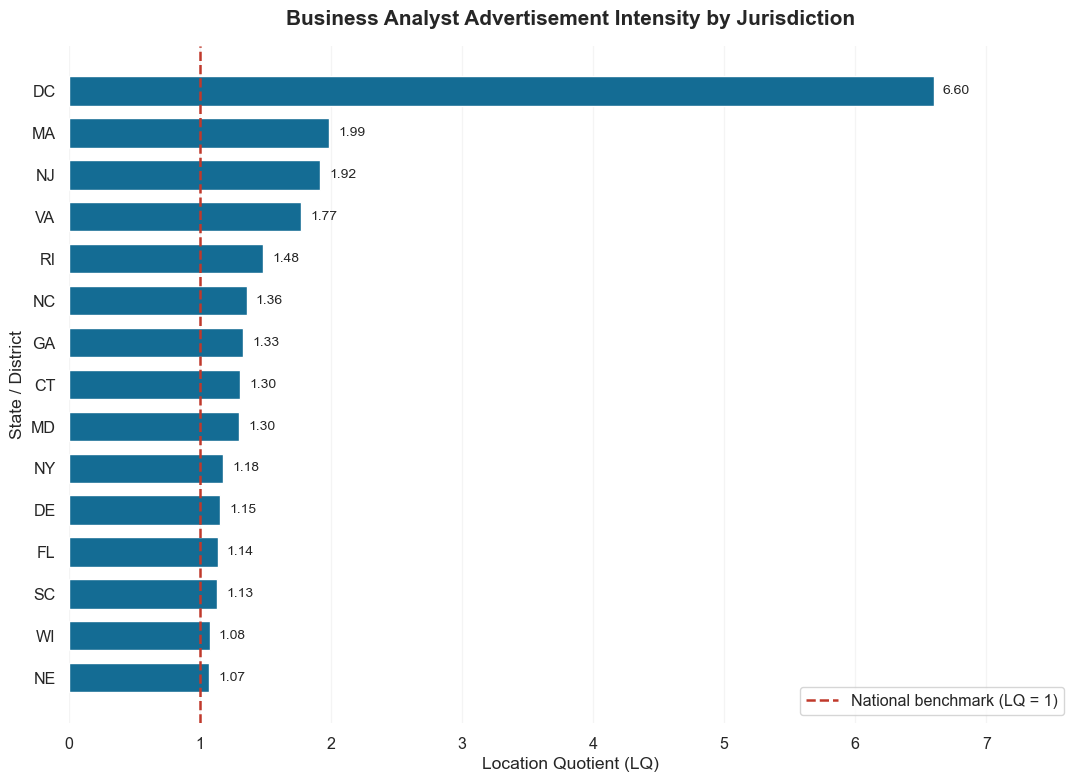

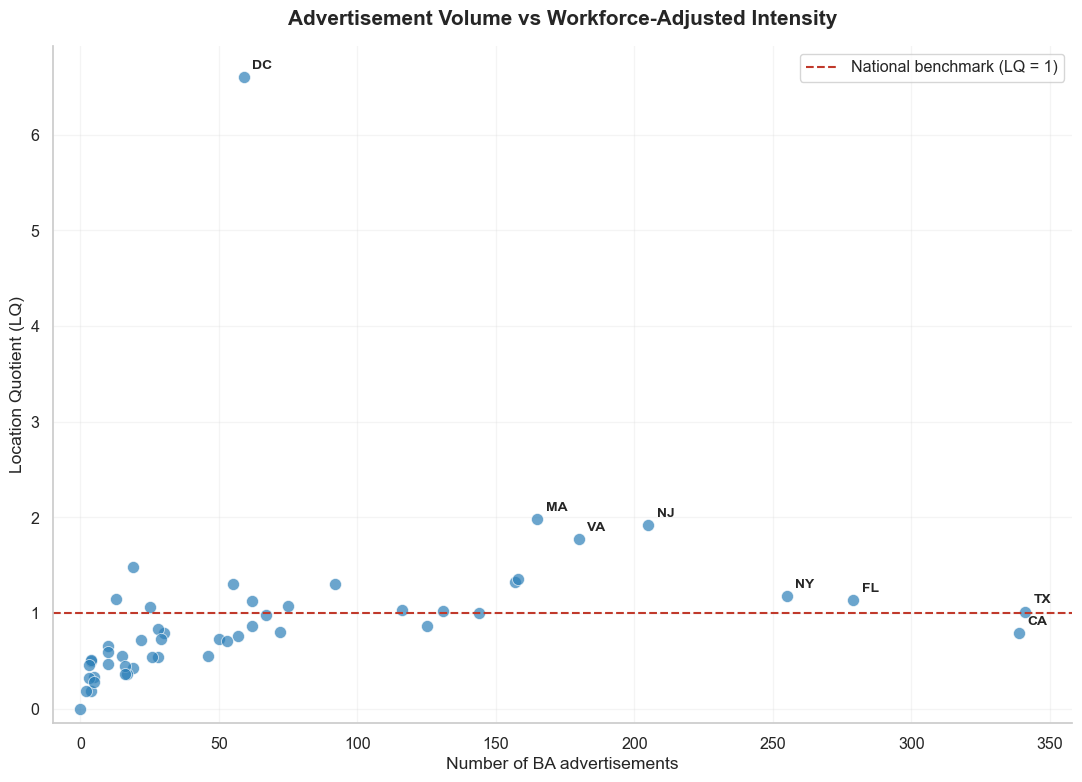

Comparison of absolute and relative rankings:


,State,Advertisements,Volume_Rank,Ads_per_100k,Location_Quotient,LQ_Rank
43,TX,341,1,2.252,1.016,18
4,CA,339,2,1.751,0.790,26
9,FL,279,3,2.519,1.137,12
32,NY,255,4,2.615,1.180,10
30,NJ,205,5,4.249,1.918,3
46,VA,180,6,3.923,1.770,4
21,MA,165,7,4.400,1.986,2
8,DC,59,20,14.623,6.599,1



Figures 2 and 3 saved successfully.


In [10]:

# ============================================================
# RQ1 - STEP 4.3D: WORKFORCE-ADJUSTED VISUALISATIONS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)

# ------------------------------------------------------------
# FIGURE 2: TOP 15 JURISDICTIONS BY LOCATION QUOTIENT
# ------------------------------------------------------------

top_lq = (
    rq1_state
    .sort_values("Location_Quotient", ascending=False)
    .head(15)
    .sort_values("Location_Quotient")
)

fig, ax = plt.subplots(figsize=(11, 8))

colors = [
    "#146C94" if value > 1 else "#9AA5B1"
    for value in top_lq["Location_Quotient"]
]

bars = ax.barh(
    top_lq["State"],
    top_lq["Location_Quotient"],
    color=colors,
    height=0.7
)

ax.axvline(
    x=1,
    color="#C0392B",
    linestyle="--",
    linewidth=1.8,
    label="National benchmark (LQ = 1)"
)

for bar, value in zip(
    bars, top_lq["Location_Quotient"]
):
    ax.text(
        value + 0.07,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Business Analyst Advertisement Intensity by Jurisdiction",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Location Quotient (LQ)")
ax.set_ylabel("State / District")
ax.set_xlim(
    0,
    top_lq["Location_Quotient"].max() * 1.16
)

ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)
plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "RQ1_Figure_2_Location_Quotients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FIGURE 3: ABSOLUTE VOLUME VS RELATIVE INTENSITY
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 8))

# All jurisdictions
ax.scatter(
    rq1_state["Advertisements"],
    rq1_state["Location_Quotient"],
    s=75,
    color="#2C7FB8",
    alpha=0.7,
    edgecolor="white",
    linewidth=0.6
)

# Highlight selected jurisdictions
highlight_states = [
    "DC", "MA", "NJ", "VA",
    "TX", "CA", "FL", "NY"
]

for state in highlight_states:
    row = rq1_state.loc[
        rq1_state["State"] == state
    ].iloc[0]

    ax.annotate(
        state,
        (
            row["Advertisements"],
            row["Location_Quotient"]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

ax.axhline(
    y=1,
    color="#C0392B",
    linestyle="--",
    linewidth=1.5,
    label="National benchmark (LQ = 1)"
)

ax.set_title(
    "Advertisement Volume vs Workforce-Adjusted Intensity",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of BA advertisements")
ax.set_ylabel("Location Quotient (LQ)")
ax.set_xlim(left=-10)
ax.set_ylim(bottom=-0.15)

ax.legend()
ax.grid(alpha=0.2)

sns.despine()
plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "RQ1_Figure_3_Volume_vs_Intensity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# COMPARISON TABLE: VOLUME RANK VS LQ RANK
# ------------------------------------------------------------

rq1_state["Volume_Rank"] = (
    rq1_state["Advertisements"]
    .rank(method="min", ascending=False)
    .astype(int)
)

rq1_state["LQ_Rank"] = (
    rq1_state["Location_Quotient"]
    .rank(method="min", ascending=False)
    .astype(int)
)

comparison = rq1_state.loc[
    rq1_state["State"].isin(highlight_states),
    [
        "State",
        "Advertisements",
        "Volume_Rank",
        "Ads_per_100k",
        "Location_Quotient",
        "LQ_Rank"
    ]
].sort_values("Volume_Rank")

print("Comparison of absolute and relative rankings:")
display(comparison.round(3))

comparison.to_csv(
    OUTPUT_DIR / "RQ1_VOLUME_VS_LQ_COMPARISON.csv",
    index=False
)

print("\nFigures 2 and 3 saved successfully.")


In [11]:

# ============================================================
# RQ1 - STEP 4.4A: GEOGRAPHIC STATISTICAL TESTING
# Spearman correlation and chi-square goodness-of-fit
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import spearmanr, chisquare

# Work from the validated 51-jurisdiction dataset
rq1_stats = rq1_state.copy()

# Check essential data
assert len(rq1_stats) == 51
assert rq1_stats["State"].is_unique
assert rq1_stats["Advertisements"].sum() == 3708
assert rq1_stats["Labour_Force"].notna().all()
assert (rq1_stats["Labour_Force"] > 0).all()

# ------------------------------------------------------------
# 1. SPEARMAN RANK CORRELATION
# ------------------------------------------------------------

rho, spearman_p = spearmanr(
    rq1_stats["Labour_Force"],
    rq1_stats["Advertisements"]
)

print("=" * 65)
print("TEST 1: SPEARMAN RANK CORRELATION")
print("=" * 65)

print(f"Spearman rho: {rho:.4f}")
print(f"P-value: {spearman_p:.6g}")

print("\nHypotheses:")
print("H0: No monotonic association between labour force")
print("    size and BA advertisement counts.")
print("H1: A monotonic association exists.")

# ------------------------------------------------------------
# 2. EXPECTED COUNTS UNDER WORKFORCE PROPORTIONALITY
# ------------------------------------------------------------

total_ads = rq1_stats["Advertisements"].sum()
total_workforce = rq1_stats["Labour_Force"].sum()

rq1_stats["Expected_Ads"] = (
    total_ads
    * rq1_stats["Labour_Force"]
    / total_workforce
)

assert np.isclose(
    rq1_stats["Expected_Ads"].sum(),
    total_ads
)

# ------------------------------------------------------------
# 3. CHI-SQUARE GOODNESS-OF-FIT
# ------------------------------------------------------------

chi2_stat, chi2_p = chisquare(
    f_obs=rq1_stats["Advertisements"],
    f_exp=rq1_stats["Expected_Ads"]
)

df = len(rq1_stats) - 1

print("\n" + "=" * 65)
print("TEST 2: CHI-SQUARE GOODNESS-OF-FIT")
print("=" * 65)

print(f"Chi-square statistic: {chi2_stat:.4f}")
print(f"Degrees of freedom: {df}")
print(f"P-value: {chi2_p:.6g}")

print("\nHypotheses:")
print("H0: BA advertisements are distributed across")
print("    jurisdictions in proportion to labour-force size.")
print("H1: The distribution differs from that benchmark.")

# Check expected-count assumptions
print("\nExpected-count diagnostics:")
print(
    "Minimum expected count:",
    round(rq1_stats["Expected_Ads"].min(), 3)
)
print(
    "Jurisdictions with expected count < 5:",
    (rq1_stats["Expected_Ads"] < 5).sum()
)

# ------------------------------------------------------------
# 4. CHI-SQUARE CONTRIBUTIONS
# ------------------------------------------------------------

rq1_stats["Chi2_Contribution"] = (
    (rq1_stats["Advertisements"] - rq1_stats["Expected_Ads"]) ** 2
    / rq1_stats["Expected_Ads"]
)

rq1_stats["Pearson_Residual"] = (
    (rq1_stats["Advertisements"] - rq1_stats["Expected_Ads"])
    / np.sqrt(rq1_stats["Expected_Ads"])
)

print("\nTop 15 contributors to geographic deviation:")

display(
    rq1_stats.sort_values(
        "Chi2_Contribution",
        ascending=False
    )[[
        "State",
        "Advertisements",
        "Expected_Ads",
        "Location_Quotient",
        "Pearson_Residual",
        "Chi2_Contribution"
    ]].head(15).round(3)
)

# ------------------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------------------

rq1_stats.to_csv(
    OUTPUT_DIR / "RQ1_GEOGRAPHIC_STATISTICAL_BASE.csv",
    index=False
)

test_summary = pd.DataFrame({
    "Test": [
        "Spearman rank correlation",
        "Chi-square goodness-of-fit"
    ],
    "Statistic": [rho, chi2_stat],
    "P_Value": [spearman_p, chi2_p],
    "Degrees_of_Freedom": [np.nan, df]
})

test_summary.to_csv(
    OUTPUT_DIR / "RQ1_GLOBAL_STATISTICAL_TESTS.csv",
    index=False
)

print("\nStatistical results saved successfully.")


TEST 1: SPEARMAN RANK CORRELATION
Spearman rho: 0.9088
P-value: 3.07912e-20

Hypotheses:
H0: No monotonic association between labour force
    size and BA advertisement counts.
H1: A monotonic association exists.

TEST 2: CHI-SQUARE GOODNESS-OF-FIT
Chi-square statistic: 791.1783
Degrees of freedom: 50
P-value: 5.83552e-134

Hypotheses:
H0: BA advertisements are distributed across
    jurisdictions in proportion to labour-force size.
H1: The distribution differs from that benchmark.

Expected-count diagnostics:
Minimum expected count: 6.513
Jurisdictions with expected count < 5: 0

Top 15 contributors to geographic deviation:


,State,Advertisements,Expected_Ads,Location_Quotient,Pearson_Residual,Chi2_Contribution
8,DC,59,8.940,6.599,16.742,280.303
30,NJ,205,106.909,1.918,9.487,90.001
21,MA,165,83.100,1.986,8.984,80.717
46,VA,180,101.668,1.770,7.769,60.353
4,CA,339,428.928,0.790,-4.342,18.854
18,LA,17,46.076,0.369,-4.283,18.348
36,OK,16,43.955,0.364,-4.217,17.780
2,AZ,46,82.575,0.557,-4.025,16.200
17,KY,19,44.847,0.424,-3.860,14.897
33,NC,158,116.419,1.357,3.854,14.851



Statistical results saved successfully.


In [12]:

# ============================================================
# RQ1 - STEP 4.4B: STATE-LEVEL STATISTICAL TESTS
# Exact Poisson tests, Holm correction, and 95% CIs
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import poisson, chi2
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. START WITH VALIDATED GEOGRAPHIC RESULTS
# ------------------------------------------------------------

rq1_poisson = rq1_stats.copy()

assert len(rq1_poisson) == 51
assert rq1_poisson["Advertisements"].sum() == 3708
assert (rq1_poisson["Expected_Ads"] > 0).all()

# ------------------------------------------------------------
# 2. EXACT TWO-SIDED POISSON TEST
# ------------------------------------------------------------

def poisson_two_sided_pvalue(observed, expected):
    """
    Conservative exact two-sided Poisson test:
    2 * smaller one-sided tail probability, capped at 1.
    """
    observed = int(observed)
    expected = float(expected)

    lower_tail = poisson.cdf(observed, expected)
    upper_tail = poisson.sf(observed - 1, expected)

    return min(1.0, 2.0 * min(lower_tail, upper_tail))


rq1_poisson["Poisson_P"] = [
    poisson_two_sided_pvalue(obs, exp)
    for obs, exp in zip(
        rq1_poisson["Advertisements"],
        rq1_poisson["Expected_Ads"]
    )
]

# ------------------------------------------------------------
# 3. HOLM MULTIPLE-TESTING CORRECTION
# ------------------------------------------------------------

reject, adjusted_p, _, _ = multipletests(
    rq1_poisson["Poisson_P"],
    alpha=0.05,
    method="holm"
)

rq1_poisson["Holm_Adjusted_P"] = adjusted_p
rq1_poisson["Significant_Holm"] = reject

# ------------------------------------------------------------
# 4. EXACT 95% POISSON CONFIDENCE INTERVALS
# ------------------------------------------------------------

def poisson_count_ci(count, alpha=0.05):
    """
    Garwood exact confidence interval for a Poisson mean.
    Supports zero observed counts.
    """
    count = int(count)

    lower = (
        0.0 if count == 0
        else 0.5 * chi2.ppf(alpha / 2, 2 * count)
    )

    upper = 0.5 * chi2.ppf(
        1 - alpha / 2,
        2 * (count + 1)
    )

    return lower, upper


confidence_intervals = [
    poisson_count_ci(count)
    for count in rq1_poisson["Advertisements"]
]

rq1_poisson["Count_CI_Lower"] = [
    ci[0] for ci in confidence_intervals
]

rq1_poisson["Count_CI_Upper"] = [
    ci[1] for ci in confidence_intervals
]

# Convert count intervals to LQ intervals
rq1_poisson["LQ_CI_Lower"] = (
    rq1_poisson["Count_CI_Lower"]
    / rq1_poisson["Expected_Ads"]
)

rq1_poisson["LQ_CI_Upper"] = (
    rq1_poisson["Count_CI_Upper"]
    / rq1_poisson["Expected_Ads"]
)

# ------------------------------------------------------------
# 5. CLASSIFY RELATIVE INTENSITY
# ------------------------------------------------------------

rq1_poisson["Direction"] = np.where(
    rq1_poisson["Advertisements"]
    > rq1_poisson["Expected_Ads"],
    "Above expected",
    np.where(
        rq1_poisson["Advertisements"]
        < rq1_poisson["Expected_Ads"],
        "Below expected",
        "As expected"
    )
)

rq1_poisson["Statistical_Category"] = np.select(
    [
        rq1_poisson["Significant_Holm"]
        & (rq1_poisson["Location_Quotient"] > 1),

        rq1_poisson["Significant_Holm"]
        & (rq1_poisson["Location_Quotient"] < 1)
    ],
    [
        "Significantly above expected",
        "Significantly below expected"
    ],
    default="Not statistically significant"
)

# ------------------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------------------

print("=" * 65)
print("RQ1 - EXACT POISSON TESTS WITH HOLM CORRECTION")
print("=" * 65)

print("Jurisdictions tested:", len(rq1_poisson))

print(
    "Significantly above expected:",
    (
        rq1_poisson["Statistical_Category"]
        == "Significantly above expected"
    ).sum()
)

print(
    "Significantly below expected:",
    (
        rq1_poisson["Statistical_Category"]
        == "Significantly below expected"
    ).sum()
)

print(
    "Not statistically significant:",
    (
        rq1_poisson["Statistical_Category"]
        == "Not statistically significant"
    ).sum()
)

# ------------------------------------------------------------
# 7. DISPLAY TOP 15 BY LOCATION QUOTIENT
# ------------------------------------------------------------

result_columns = [
    "State",
    "Advertisements",
    "Expected_Ads",
    "Location_Quotient",
    "LQ_CI_Lower",
    "LQ_CI_Upper",
    "Poisson_P",
    "Holm_Adjusted_P",
    "Statistical_Category"
]

print("\nTop 15 jurisdictions by Location Quotient:")

display(
    rq1_poisson
    .sort_values("Location_Quotient", ascending=False)
    [result_columns]
    .head(15)
    .round(4)
)

# ------------------------------------------------------------
# 8. DISPLAY ALL SIGNIFICANT JURISDICTIONS
# ------------------------------------------------------------

print("\nAll Holm-significant jurisdictions:")

display(
    rq1_poisson.loc[
        rq1_poisson["Significant_Holm"],
        result_columns
    ]
    .sort_values("Holm_Adjusted_P")
    .round(4)
)

# ------------------------------------------------------------
# 9. VALIDATE AND SAVE
# ------------------------------------------------------------

assert rq1_poisson["Poisson_P"].between(0, 1).all()
assert rq1_poisson["Holm_Adjusted_P"].between(0, 1).all()
assert (
    rq1_poisson["LQ_CI_Lower"]
    <= rq1_poisson["Location_Quotient"]
).all()
assert (
    rq1_poisson["LQ_CI_Upper"]
    >= rq1_poisson["Location_Quotient"]
).all()

rq1_poisson.to_csv(
    OUTPUT_DIR / "RQ1_POISSON_HOLM_RESULTS.csv",
    index=False
)

print("\nAll validation checks passed.")
print("Poisson results saved successfully.")


RQ1 - EXACT POISSON TESTS WITH HOLM CORRECTION
Jurisdictions tested: 51
Significantly above expected: 6
Significantly below expected: 11
Not statistically significant: 34

Top 15 jurisdictions by Location Quotient:


,State,Advertisements,Expected_Ads,Location_Quotient,LQ_CI_Lower,LQ_CI_Upper,Poisson_P,Holm_Adjusted_P,Statistical_Category
8,DC,59,8.9402,6.5994,5.0237,8.5127,0.0000,0.0000,Significantly above expected
21,MA,165,83.1001,1.9856,1.6941,2.3127,0.0000,0.0000,Significantly above expected
30,NJ,205,106.9089,1.9175,1.6640,2.1987,0.0000,0.0000,Significantly above expected
46,VA,180,101.6677,1.7705,1.5213,2.0489,0.0000,0.0000,Significantly above expected
39,RI,19,12.8185,1.4822,0.8924,2.3147,0.1258,1.0000,Not statistically significant
33,NC,158,116.4189,1.3572,1.1538,1.5861,0.0003,0.0115,Significantly above expected
10,GA,157,118.1019,1.3294,1.1296,1.5543,0.0007,0.0267,Significantly above expected
6,CT,55,42.1528,1.3048,0.9829,1.6983,0.0653,1.0000,Not statistically significant
20,MD,92,70.7467,1.3004,1.0483,1.5948,0.0174,0.4868,Not statistically significant
32,NY,255,216.0804,1.1801,1.0397,1.3342,0.0107,0.3209,Not statistically significant



All Holm-significant jurisdictions:


,State,Advertisements,Expected_Ads,Location_Quotient,LQ_CI_Lower,LQ_CI_Upper,Poisson_P,Holm_Adjusted_P,Statistical_Category
8,DC,59,8.9402,6.5994,5.0237,8.5127,0.0000,0.0000,Significantly above expected
30,NJ,205,106.9089,1.9175,1.6640,2.1987,0.0000,0.0000,Significantly above expected
21,MA,165,83.1001,1.9856,1.6941,2.3127,0.0000,0.0000,Significantly above expected
46,VA,180,101.6677,1.7705,1.5213,2.0489,0.0000,0.0000,Significantly above expected
18,LA,17,46.0761,0.3690,0.2149,0.5907,0.0000,0.0001,Significantly below expected
36,OK,16,43.9555,0.3640,0.2081,0.5911,0.0000,0.0001,Significantly below expected
26,MT,0,12.7913,0.0000,0.0000,0.2884,0.0000,0.0003,Significantly below expected
4,CA,339,428.9275,0.7903,0.7084,0.8791,0.0000,0.0003,Significantly below expected
31,NM,4,21.4696,0.1863,0.0508,0.4770,0.0000,0.0004,Significantly below expected
2,AZ,46,82.5754,0.5571,0.4078,0.7430,0.0000,0.0007,Significantly below expected



All validation checks passed.
Poisson results saved successfully.


In [13]:

# ============================================================
# RQ1 - STEP 4.5A: GEOGRAPHIC SENSITIVITY ANALYSIS
# ============================================================
# Objectives:
# 1. Identify the largest BA advertiser
# 2. Remove its advertisements
# 3. Recalculate state-level Location Quotients (LQs)
# 4. Compare original and revised geographic rankings
# 5. Recalculate the chi-square goodness-of-fit test
# 6. Compare Poisson and exact binomial significance results
# 7. Save all results for the final report
# ============================================================

import pandas as pd
import numpy as np

from scipy.stats import chisquare, binomtest
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. VALIDATE EXISTING DATASETS
# ------------------------------------------------------------

assert "company" in us_ba_geo.columns
assert "state_clean" in us_ba_geo.columns
assert len(us_ba_geo) == 3722

assert len(rq1_state) == 51
assert rq1_state["Advertisements"].sum() == 3708

assert len(rq1_poisson) == 51
assert "Significant_Holm" in rq1_poisson.columns

print("=" * 65)
print("RQ1 - GEOGRAPHIC SENSITIVITY ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 2. CLEAN ADVERTISER NAMES
# ------------------------------------------------------------

geo_sensitivity = us_ba_geo.copy()

geo_sensitivity["company_clean"] = (
    geo_sensitivity["company"]
    .fillna("Unknown advertiser")
    .astype(str)
    .str.strip()
)

geo_sensitivity.loc[
    geo_sensitivity["company_clean"] == "",
    "company_clean"
] = "Unknown advertiser"

# ------------------------------------------------------------
# 3. IDENTIFY TOP ADVERTISERS
# ------------------------------------------------------------

advertiser_counts = (
    geo_sensitivity["company_clean"]
    .value_counts()
)

advertiser_summary = (
    advertiser_counts
    .rename_axis("Company")
    .reset_index(name="Advertisements")
)

advertiser_summary["Share_Pct"] = (
    advertiser_summary["Advertisements"]
    / len(geo_sensitivity) * 100
)

print("\nTOP 10 BA ADVERTISERS:")
display(advertiser_summary.head(10).round(2))

# Exclude missing advertiser names from the ranking
known_advertisers = advertiser_summary.loc[
    advertiser_summary["Company"] != "Unknown advertiser"
]

assert not known_advertisers.empty

largest_advertiser = known_advertisers.iloc[0]["Company"]
largest_count = int(
    known_advertisers.iloc[0]["Advertisements"]
)

largest_share = (
    largest_count / len(geo_sensitivity) * 100
)

print("\nLargest known advertiser:", largest_advertiser)
print("Advertisements:", largest_count)
print(f"Share of all BA advertisements: {largest_share:.2f}%")

# ------------------------------------------------------------
# 4. REMOVE THE LARGEST ADVERTISER
# ------------------------------------------------------------

geo_without_top = geo_sensitivity.loc[
    geo_sensitivity["company_clean"] != largest_advertiser
].copy()

print("\nOriginal BA advertisements:", len(geo_sensitivity))
print("Remaining advertisements:", len(geo_without_top))
print("Advertisements removed:", largest_count)

# ------------------------------------------------------------
# 5. RECOMPUTE STATE COUNTS
# ------------------------------------------------------------

revised_counts = (
    geo_without_top["state_clean"]
    .value_counts()
    .rename_axis("State")
    .reset_index(name="Ads_Without_Top")
)

sensitivity = rq1_state[[
    "State",
    "Advertisements",
    "Labour_Force",
    "Location_Quotient"
]].copy()

sensitivity = sensitivity.rename(columns={
    "Advertisements": "Original_Ads",
    "Location_Quotient": "Original_LQ"
})

# Preserve all 51 jurisdictions
sensitivity = sensitivity.merge(
    revised_counts,
    on="State",
    how="left",
    validate="one_to_one"
)

sensitivity["Ads_Without_Top"] = (
    sensitivity["Ads_Without_Top"]
    .fillna(0)
    .astype(int)
)

# ------------------------------------------------------------
# 6. CALCULATE REVISED EXPECTED COUNTS AND LQs
# ------------------------------------------------------------

original_ads = sensitivity["Original_Ads"].sum()
remaining_ads = sensitivity["Ads_Without_Top"].sum()

national_workforce = sensitivity["Labour_Force"].sum()

sensitivity["Expected_Without_Top"] = (
    remaining_ads
    * sensitivity["Labour_Force"]
    / national_workforce
)

sensitivity["Revised_LQ"] = (
    sensitivity["Ads_Without_Top"]
    / sensitivity["Expected_Without_Top"]
)

sensitivity["LQ_Change"] = (
    sensitivity["Revised_LQ"]
    - sensitivity["Original_LQ"]
)

sensitivity["LQ_Change_Pct"] = np.where(
    sensitivity["Original_LQ"] > 0,
    (
        sensitivity["Revised_LQ"]
        / sensitivity["Original_LQ"] - 1
    ) * 100,
    np.nan
)

# ------------------------------------------------------------
# 7. RECOMPUTE CHI-SQUARE GOODNESS-OF-FIT
# ------------------------------------------------------------

chi2_revised, p_revised = chisquare(
    f_obs=sensitivity["Ads_Without_Top"],
    f_exp=sensitivity["Expected_Without_Top"]
)

chi2_original, p_original = chisquare(
    f_obs=rq1_state["Advertisements"],
    f_exp=(
        original_ads
        * rq1_state["Labour_Force"]
        / national_workforce
    )
)

print("\n" + "=" * 65)
print("ORIGINAL VS REVISED CHI-SQUARE")
print("=" * 65)

print(f"Original state-identified ads: {original_ads:,}")
print(f"Remaining state-identified ads: {remaining_ads:,}")

print(f"\nOriginal chi-square: {chi2_original:.3f}")
print(f"Original p-value: {p_original:.6g}")

print(f"\nRevised chi-square: {chi2_revised:.3f}")
print(f"Revised p-value: {p_revised:.6g}")

# ------------------------------------------------------------
# 8. COMPARE GEOGRAPHIC RANKINGS
# ------------------------------------------------------------

sensitivity["Original_LQ_Rank"] = (
    sensitivity["Original_LQ"]
    .rank(ascending=False, method="min")
    .astype(int)
)

sensitivity["Revised_LQ_Rank"] = (
    sensitivity["Revised_LQ"]
    .rank(ascending=False, method="min")
    .astype(int)
)

sensitivity["Rank_Change"] = (
    sensitivity["Original_LQ_Rank"]
    - sensitivity["Revised_LQ_Rank"]
)

print("\nTOP 15 JURISDICTIONS BY REVISED LQ:")

display(
    sensitivity
    .sort_values("Revised_LQ", ascending=False)
    [[
        "State",
        "Original_Ads",
        "Ads_Without_Top",
        "Original_LQ",
        "Revised_LQ",
        "LQ_Change",
        "Original_LQ_Rank",
        "Revised_LQ_Rank",
        "Rank_Change"
    ]]
    .head(15)
    .round(3)
)

print("\nLARGEST ABSOLUTE LQ CHANGES:")

display(
    sensitivity
    .assign(
        Absolute_LQ_Change=lambda x: x["LQ_Change"].abs()
    )
    .sort_values("Absolute_LQ_Change", ascending=False)
    [[
        "State",
        "Original_LQ",
        "Revised_LQ",
        "LQ_Change",
        "Rank_Change"
    ]]
    .head(10)
    .round(3)
)

# ------------------------------------------------------------
# 9. EXACT BINOMIAL ALLOCATION TESTS
# ------------------------------------------------------------
# Unlike the Poisson model, this conditions on the fixed
# national total of state-identified BA advertisements.
# ------------------------------------------------------------

national_ads = int(rq1_state["Advertisements"].sum())

workforce_probabilities = (
    rq1_state["Labour_Force"]
    / rq1_state["Labour_Force"].sum()
)

binomial_pvalues = [
    binomtest(
        k=int(count),
        n=national_ads,
        p=float(probability),
        alternative="two-sided"
    ).pvalue
    for count, probability in zip(
        rq1_state["Advertisements"],
        workforce_probabilities
    )
]

reject_binomial, adjusted_binomial_p, _, _ = multipletests(
    binomial_pvalues,
    alpha=0.05,
    method="holm"
)

binomial_results = rq1_state[[
    "State",
    "Advertisements",
    "Location_Quotient"
]].copy()

binomial_results["Binomial_P"] = binomial_pvalues
binomial_results["Binomial_Holm_P"] = adjusted_binomial_p
binomial_results["Binomial_Significant"] = reject_binomial

# ------------------------------------------------------------
# 10. COMPARE POISSON AND BINOMIAL RESULTS
# ------------------------------------------------------------

poisson_significant = set(
    rq1_poisson.loc[
        rq1_poisson["Significant_Holm"],
        "State"
    ]
)

binomial_significant = set(
    binomial_results.loc[
        binomial_results["Binomial_Significant"],
        "State"
    ]
)

print("\n" + "=" * 65)
print("POISSON VS EXACT BINOMIAL COMPARISON")
print("=" * 65)

print("Poisson significant:", len(poisson_significant))
print("Binomial significant:", len(binomial_significant))

print(
    "Significant in both:",
    len(poisson_significant & binomial_significant)
)

print(
    "Poisson only:",
    sorted(poisson_significant - binomial_significant)
)

print(
    "Binomial only:",
    sorted(binomial_significant - poisson_significant)
)

# ------------------------------------------------------------
# 11. VALIDATE AND SAVE RESULTS
# ------------------------------------------------------------

assert len(sensitivity) == 51
assert sensitivity["Original_Ads"].sum() == 3708

assert remaining_ads <= original_ads
assert (sensitivity["Ads_Without_Top"] >= 0).all()
assert sensitivity["Revised_LQ"].notna().all()

assert np.isclose(
    sensitivity["Expected_Without_Top"].sum(),
    remaining_ads
)

assert len(binomial_results) == 51
assert binomial_results["Binomial_P"].between(0, 1).all()
assert binomial_results["Binomial_Holm_P"].between(0, 1).all()

advertiser_summary.to_csv(
    OUTPUT_DIR / "RQ1_ADVERTISER_SUMMARY.csv",
    index=False
)

sensitivity.to_csv(
    OUTPUT_DIR / "RQ1_ADVERTISER_SENSITIVITY.csv",
    index=False
)

binomial_results.to_csv(
    OUTPUT_DIR / "RQ1_BINOMIAL_ROBUSTNESS.csv",
    index=False
)

print("\n" + "=" * 65)
print("ALL VALIDATION CHECKS PASSED")
print("Results saved successfully.")
print("=" * 65)


RQ1 - GEOGRAPHIC SENSITIVITY ANALYSIS

TOP 10 BA ADVERTISERS:


,Company,Advertisements,Share_Pct
0,LATICRETE International,312,8.38
1,Dice,165,4.43
2,Tata Consultancy Services,68,1.83
3,Stellent IT,59,1.59
4,NR Consulting,58,1.56
5,Jobs for Humanity,44,1.18
6,Software Technology Inc.,40,1.07
7,Diverse Lynx,37,0.99
8,Robert Half,35,0.94
9,CERES Group,28,0.75



Largest known advertiser: LATICRETE International
Advertisements: 312
Share of all BA advertisements: 8.38%

Original BA advertisements: 3722
Remaining advertisements: 3410
Advertisements removed: 312

ORIGINAL VS REVISED CHI-SQUARE
Original state-identified ads: 3,708
Remaining state-identified ads: 3,396

Original chi-square: 791.178
Original p-value: 5.83552e-134

Revised chi-square: 881.905
Revised p-value: 1.56208e-152

TOP 15 JURISDICTIONS BY REVISED LQ:


,State,Original_Ads,Ads_Without_Top,Original_LQ,Revised_LQ,LQ_Change,Original_LQ_Rank,Revised_LQ_Rank,Rank_Change
8,DC,59,57,6.599,6.961,0.362,1,1,0
21,MA,165,161,1.986,2.115,0.130,2,2,0
30,NJ,205,199,1.918,2.032,0.115,3,3,0
46,VA,180,176,1.770,1.890,0.120,4,4,0
39,RI,19,19,1.482,1.618,0.136,5,5,0
10,GA,157,157,1.329,1.451,0.122,7,6,1
20,MD,92,90,1.300,1.389,0.089,9,7,2
33,NC,158,146,1.357,1.369,0.012,6,8,-2
6,CT,55,52,1.305,1.347,0.042,8,9,-1
7,DE,13,13,1.153,1.259,0.106,11,10,1



LARGEST ABSOLUTE LQ CHANGES:


,State,Original_LQ,Revised_LQ,LQ_Change,Rank_Change
8,DC,6.599,6.961,0.362,0
28,NV,0.447,0.214,-0.234,-6
40,SC,1.132,0.937,-0.195,-7
37,OR,0.540,0.363,-0.177,-5
44,UT,0.726,0.574,-0.152,-4
39,RI,1.482,1.618,0.136,0
21,MA,1.986,2.115,0.130,0
10,GA,1.329,1.451,0.122,1
46,VA,1.770,1.890,0.120,0
11,HI,0.334,0.219,-0.115,-1



POISSON VS EXACT BINOMIAL COMPARISON
Poisson significant: 17
Binomial significant: 17
Significant in both: 17
Poisson only: []
Binomial only: []

ALL VALIDATION CHECKS PASSED
Results saved successfully.


In [14]:

# ============================================================
# RQ1 - STEP 4.5B: UNIQUE ADVERTISER ROBUSTNESS
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import chisquare, spearmanr

# 1. Use the prepared data from Step 4.5A
advertiser_geo = geo_sensitivity.copy()

# Exclude records without a known advertiser or state
advertiser_geo = advertiser_geo.loc[
    advertiser_geo["company_clean"].ne("Unknown advertiser")
    & advertiser_geo["state_clean"].isin(rq1_state["State"])
].copy()

# Standardise names conservatively for counting
advertiser_geo["company_key"] = (
    advertiser_geo["company_clean"]
    .str.strip()
    .str.casefold()
)

# 2. Count unique advertisers per jurisdiction
unique_pairs = advertiser_geo.drop_duplicates(
    subset=["state_clean", "company_key"]
)

unique_counts = (
    unique_pairs.groupby("state_clean")["company_key"]
    .nunique()
    .rename("Unique_Advertisers")
    .reset_index()
    .rename(columns={"state_clean": "State"})
)

# 3. Preserve all 51 jurisdictions
robustness = rq1_state[[
    "State", "Advertisements", "Labour_Force",
    "Location_Quotient"
]].copy()

robustness = robustness.merge(
    unique_counts,
    on="State",
    how="left",
    validate="one_to_one"
)

robustness["Unique_Advertisers"] = (
    robustness["Unique_Advertisers"]
    .fillna(0)
    .astype(int)
)

# 4. Calculate workforce-adjusted advertiser intensity
total_unique_state_pairs = robustness[
    "Unique_Advertisers"
].sum()

total_workforce = robustness["Labour_Force"].sum()

robustness["Expected_Advertisers"] = (
    total_unique_state_pairs
    * robustness["Labour_Force"]
    / total_workforce
)

robustness["Advertiser_LQ"] = (
    robustness["Unique_Advertisers"]
    / robustness["Expected_Advertisers"]
)

# 5. Compare geographic rankings
robustness["Original_Rank"] = (
    robustness["Location_Quotient"]
    .rank(ascending=False, method="min")
    .astype(int)
)

robustness["Advertiser_Rank"] = (
    robustness["Advertiser_LQ"]
    .rank(ascending=False, method="min")
    .astype(int)
)

robustness["Rank_Change"] = (
    robustness["Original_Rank"]
    - robustness["Advertiser_Rank"]
)

# 6. Compare overall rankings
rank_rho, rank_p = spearmanr(
    robustness["Location_Quotient"],
    robustness["Advertiser_LQ"]
)

# 7. Descriptive chi-square comparison
# Note: unique advertiser-state pairs are not necessarily
# independent observations, so this is a diagnostic only.
chi2_unique, p_unique = chisquare(
    robustness["Unique_Advertisers"],
    robustness["Expected_Advertisers"]
)

print("=" * 65)
print("RQ1 - UNIQUE ADVERTISER ROBUSTNESS")
print("=" * 65)

print(
    "Known advertiser-state advertisement records:",
    len(advertiser_geo)
)

print(
    "Unique advertiser-state pairs:",
    total_unique_state_pairs
)

print(
    "Unique advertisers nationally:",
    advertiser_geo["company_key"].nunique()
)

print(
    "Spearman correlation between original and "
    "advertiser-adjusted LQs:",
    f"{rank_rho:.4f}"
)

print(
    "Descriptive chi-square statistic:",
    f"{chi2_unique:.3f}"
)

print(
    "Chi-square reference p-value (diagnostic only):",
    f"{p_unique:.6g}"
)

print("\nTOP 15 BY UNIQUE-ADVERTISER LQ:")

display(
    robustness.sort_values(
        "Advertiser_LQ", ascending=False
    )[[
        "State",
        "Advertisements",
        "Unique_Advertisers",
        "Location_Quotient",
        "Advertiser_LQ",
        "Original_Rank",
        "Advertiser_Rank",
        "Rank_Change"
    ]].head(15).round(3)
)

print("\nLARGEST RANK CHANGES:")

display(
    robustness.assign(
        Abs_Rank_Change=lambda x: x["Rank_Change"].abs()
    ).sort_values(
        "Abs_Rank_Change", ascending=False
    )[[
        "State",
        "Location_Quotient",
        "Advertiser_LQ",
        "Original_Rank",
        "Advertiser_Rank",
        "Rank_Change"
    ]].head(10).round(3)
)

# 8. Validate and save
assert len(robustness) == 51
assert robustness["State"].is_unique
assert robustness["Unique_Advertisers"].ge(0).all()
assert np.isfinite(robustness["Advertiser_LQ"]).all()

robustness.to_csv(
    OUTPUT_DIR / "RQ1_UNIQUE_ADVERTISER_ROBUSTNESS.csv",
    index=False
)

print("\nAll validation checks passed.")
print("Unique-advertiser robustness results saved.")


RQ1 - UNIQUE ADVERTISER ROBUSTNESS
Known advertiser-state advertisement records: 3708
Unique advertiser-state pairs: 2191
Unique advertisers nationally: 1351
Spearman correlation between original and advertiser-adjusted LQs: 0.9336
Descriptive chi-square statistic: 478.519
Chi-square reference p-value (diagnostic only): 2.73381e-71

TOP 15 BY UNIQUE-ADVERTISER LQ:


,State,Advertisements,Unique_Advertisers,Location_Quotient,Advertiser_LQ,Original_Rank,Advertiser_Rank,Rank_Change
8,DC,59,42,6.599,7.951,1,1,0
39,RI,19,17,1.482,2.244,5,2,3
21,MA,165,87,1.986,1.772,2,3,-1
7,DE,13,11,1.153,1.651,11,4,7
30,NJ,205,101,1.918,1.599,3,5,-2
20,MD,92,63,1.300,1.507,9,6,3
46,VA,180,88,1.770,1.465,4,7,-3
6,CT,55,33,1.305,1.325,8,8,0
10,GA,157,91,1.329,1.304,7,9,-2
33,NC,158,89,1.357,1.294,6,10,-4



LARGEST RANK CHANGES:


,State,Location_Quotient,Advertiser_LQ,Original_Rank,Advertiser_Rank,Rank_Change
5,CO,0.864,0.755,21,33,-12
15,IA,0.794,1.120,25,14,11
1,AK,0.504,0.853,39,28,11
42,TN,0.706,0.970,31,20,11
40,SC,1.132,0.927,13,24,-11
50,WY,0.461,0.780,41,31,10
3,AR,0.717,0.551,30,39,-9
23,MN,0.977,1.160,20,11,9
4,CA,0.790,0.738,26,34,-8
7,DE,1.153,1.651,11,4,7



All validation checks passed.
Unique-advertiser robustness results saved.


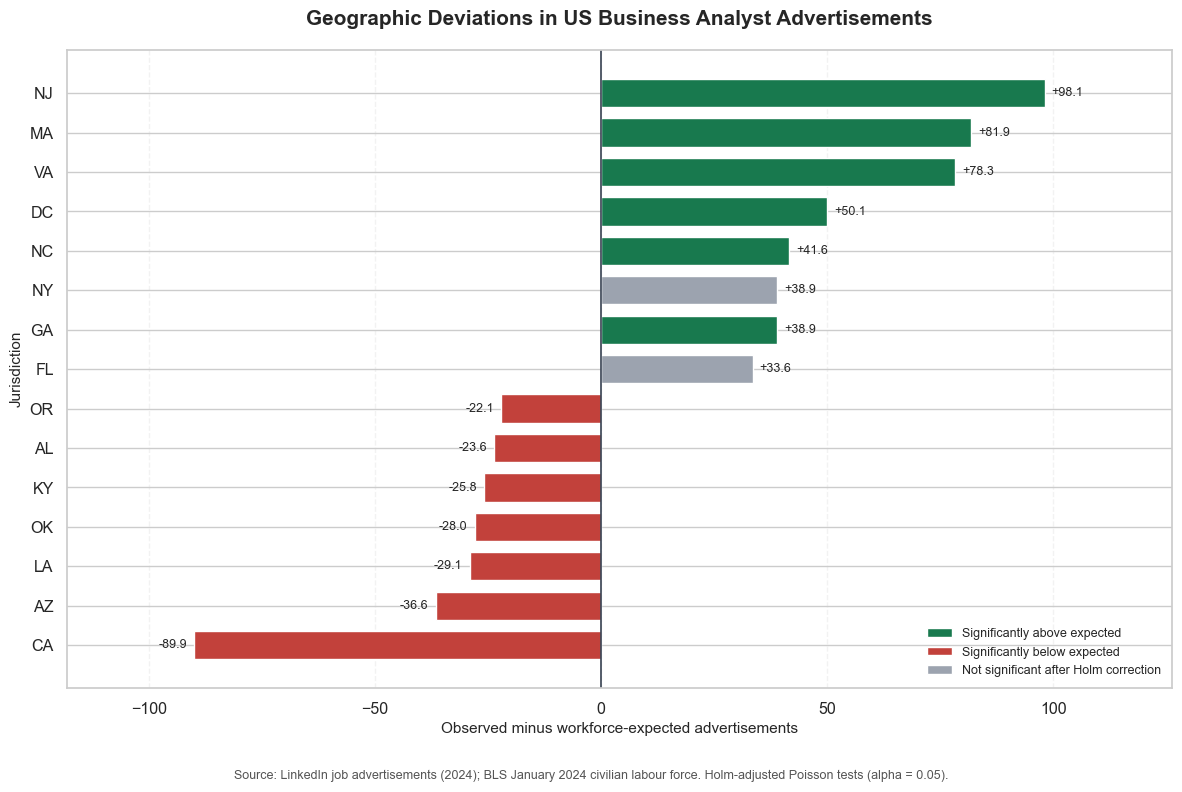

Figure saved: E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis\RQ1_Figure_4_Statistical_Deviations.png
Figure data saved successfully.


In [15]:

# ============================================================
# RQ1 - STEP 4.6: OBSERVED VS EXPECTED ADVERTISEMENTS
# Figure 4 - Statistical Geographic Deviations
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 1. Prepare data
figure_data = rq1_poisson.copy()

figure_data["Deviation"] = (
    figure_data["Advertisements"]
    - figure_data["Expected_Ads"]
)

figure_data["Absolute_Deviation"] = (
    figure_data["Deviation"].abs()
)

# Select 15 largest absolute deviations
plot_data = (
    figure_data
    .sort_values("Absolute_Deviation", ascending=False)
    .head(15)
    .sort_values("Deviation")
    .copy()
)

# 2. Assign significance colours
def significance_colour(row):
    if not row["Significant_Holm"]:
        return "#9CA3AF"
    if row["Deviation"] > 0:
        return "#18794E"
    return "#C2413B"

plot_data["Colour"] = plot_data.apply(
    significance_colour, axis=1
)

# 3. Create diverging bar chart
fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    plot_data["State"],
    plot_data["Deviation"],
    color=plot_data["Colour"],
    height=0.72
)

ax.axvline(
    0, color="#374151",
    linewidth=1.2
)

# 4. Add deviation labels
for bar, deviation in zip(
    bars, plot_data["Deviation"]
):
    y = bar.get_y() + bar.get_height() / 2

    if deviation >= 0:
        ax.annotate(
            f"+{deviation:.1f}",
            (deviation, y),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            ha="left",
            fontsize=9
        )
    else:
        ax.annotate(
            f"{deviation:.1f}",
            (deviation, y),
            xytext=(-5, 0),
            textcoords="offset points",
            va="center",
            ha="right",
            fontsize=9
        )

# 5. Styling
ax.set_title(
    "Geographic Deviations in US Business Analyst Advertisements",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Observed minus workforce-expected advertisements",
    fontsize=11
)

ax.set_ylabel("Jurisdiction", fontsize=11)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

legend_items = [
    Patch(
        facecolor="#18794E",
        label="Significantly above expected"
    ),
    Patch(
        facecolor="#C2413B",
        label="Significantly below expected"
    ),
    Patch(
        facecolor="#9CA3AF",
        label="Not significant after Holm correction"
    )
]

ax.legend(
    handles=legend_items,
    loc="lower right",
    frameon=False,
    fontsize=9
)

ax.margins(x=0.15)

fig.text(
    0.5, 0.015,
    "Source: LinkedIn job advertisements (2024); "
    "BLS January 2024 civilian labour force. "
    "Holm-adjusted Poisson tests (alpha = 0.05).",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.045, 1, 1])

# 6. Save figure
figure_path = (
    OUTPUT_DIR / "RQ1_Figure_4_Statistical_Deviations.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path)

# 7. Save figure data
plot_data.to_csv(
    OUTPUT_DIR / "RQ1_Figure_4_Data.csv",
    index=False
)

print("Figure data saved successfully.")


In [16]:

# ============================================================
# RQ2 - STEP 5.1: ADVERTISER DISTRIBUTION
# ============================================================

import pandas as pd
import numpy as np

# 1. Prepare the validated BA dataset
rq2_jobs = us_ba_geo.copy()

assert len(rq2_jobs) == 3722
assert rq2_jobs["job_link"].is_unique

# 2. Standardise advertiser names conservatively
rq2_jobs["company_clean"] = (
    rq2_jobs["company"]
    .fillna("Unknown advertiser")
    .astype(str)
    .str.strip()
)

rq2_jobs.loc[
    rq2_jobs["company_clean"].eq(""),
    "company_clean"
] = "Unknown advertiser"

# 3. Count advertisements by advertiser
advertiser_distribution = (
    rq2_jobs.groupby("company_clean")
    .agg(
        Advertisements=("job_link", "nunique")
    )
    .reset_index()
    .sort_values("Advertisements", ascending=False)
)

advertiser_distribution["Share_Pct"] = (
    advertiser_distribution["Advertisements"]
    / len(rq2_jobs) * 100
)

advertiser_distribution["Cumulative_Share_Pct"] = (
    advertiser_distribution["Share_Pct"].cumsum()
)

# 4. Summary statistics
total_advertisers = len(advertiser_distribution)

single_advertisers = (
    advertiser_distribution["Advertisements"].eq(1).sum()
)

top_1_share = (
    advertiser_distribution["Advertisements"].head(1).sum()
    / len(rq2_jobs) * 100
)

top_5_share = (
    advertiser_distribution["Advertisements"].head(5).sum()
    / len(rq2_jobs) * 100
)

top_10_share = (
    advertiser_distribution["Advertisements"].head(10).sum()
    / len(rq2_jobs) * 100
)

top_20_share = (
    advertiser_distribution["Advertisements"].head(20).sum()
    / len(rq2_jobs) * 100
)

print("=" * 65)
print("RQ2 - ADVERTISER DISTRIBUTION")
print("=" * 65)

print("Total advertisements:", len(rq2_jobs))
print("Distinct advertiser labels:", total_advertisers)
print("Single-advertisement advertisers:", single_advertisers)
print(f"Top 1 share: {top_1_share:.2f}%")
print(f"Top 5 share: {top_5_share:.2f}%")
print(f"Top 10 share: {top_10_share:.2f}%")
print(f"Top 20 share: {top_20_share:.2f}%")

print("\nTOP 20 ADVERTISERS:")
display(advertiser_distribution.head(20).round(2))

# 5. Save output
advertiser_distribution.to_csv(
    OUTPUT_DIR / "RQ2_ADVERTISER_DISTRIBUTION.csv",
    index=False
)

print("\nAdvertiser distribution saved successfully.")


RQ2 - ADVERTISER DISTRIBUTION
Total advertisements: 3722
Distinct advertiser labels: 1356
Single-advertisement advertisers: 914
Top 1 share: 8.38%
Top 5 share: 17.79%
Top 10 share: 22.73%
Top 20 share: 29.29%

TOP 20 ADVERTISERS:


,company_clean,Advertisements,Share_Pct,Cumulative_Share_Pct
638,LATICRETE International,312,8.38,8.38
329,Dice,165,4.43,12.82
1124,Tata Consultancy Services,68,1.83,14.64
1075,Stellent IT,59,1.59,16.23
767,NR Consulting,58,1.56,17.79
602,Jobs for Humanity,44,1.18,18.97
1040,Software Technology Inc.,40,1.07,20.04
337,Diverse Lynx,37,0.99,21.04
973,Robert Half,35,0.94,21.98
1076,Steneral Consulting,28,0.75,22.73



Advertiser distribution saved successfully.


RQ2 - ADVERTISER CONCENTRATION
Total advertisers: 1,356
Total advertisements: 3,722

CONCENTRATION RATIOS
CR1:  8.38%
CR5:  17.79%
CR10: 22.73%
CR20: 29.29%
CR50: 40.06%

CONCENTRATION METRICS
HHI: 116.35
Gini coefficient: 0.5656
Effective number of advertisers: 85.95


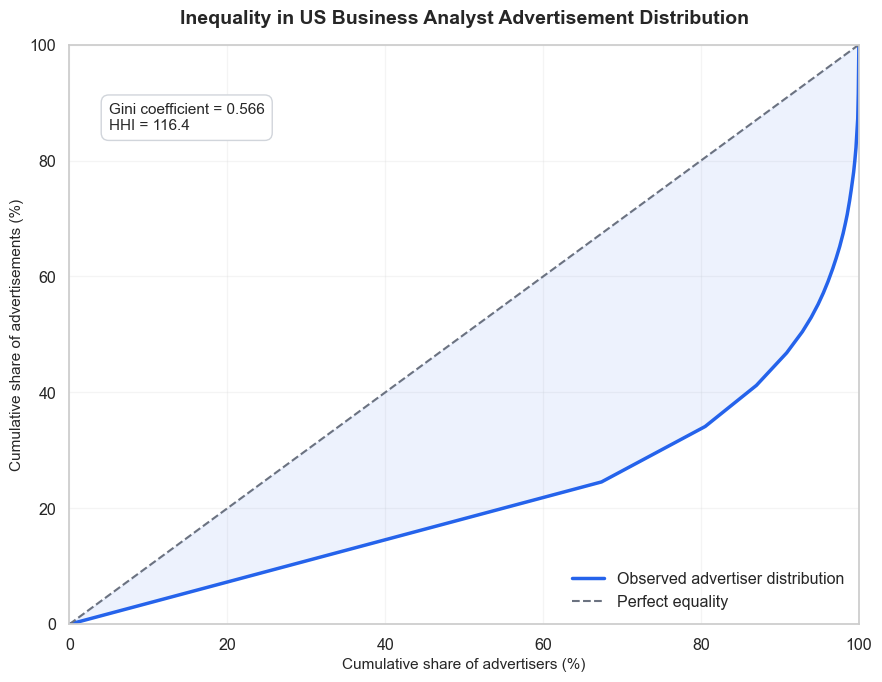


Figure and concentration summary saved successfully.


In [17]:

# ============================================================
# RQ2 - STEP 5.2: ADVERTISER CONCENTRATION ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. VALIDATE ADVERTISER DISTRIBUTION
# ------------------------------------------------------------

rq2_concentration = advertiser_distribution.copy()

assert len(rq2_concentration) == 1356
assert rq2_concentration["Advertisements"].sum() == 3722
assert (rq2_concentration["Advertisements"] > 0).all()

# Sort from largest to smallest
rq2_concentration = (
    rq2_concentration
    .sort_values("Advertisements", ascending=False)
    .reset_index(drop=True)
)

total_ads = rq2_concentration["Advertisements"].sum()
total_advertisers = len(rq2_concentration)

# ------------------------------------------------------------
# 2. CONCENTRATION RATIOS
# ------------------------------------------------------------

def concentration_ratio(n):
    return (
        rq2_concentration["Advertisements"].head(n).sum()
        / total_ads * 100
    )

cr1 = concentration_ratio(1)
cr5 = concentration_ratio(5)
cr10 = concentration_ratio(10)
cr20 = concentration_ratio(20)
cr50 = concentration_ratio(50)

# ------------------------------------------------------------
# 3. HERFINDAHL-HIRSCHMAN INDEX (HHI)
# ------------------------------------------------------------
# Share percentages are squared and summed.
# HHI ranges from near 0 to 10,000.
# ------------------------------------------------------------

shares = (
    rq2_concentration["Advertisements"]
    / total_ads
)

hhi = np.sum((shares * 100) ** 2)

effective_advertisers = 1 / np.sum(shares ** 2)

# ------------------------------------------------------------
# 4. GINI COEFFICIENT
# ------------------------------------------------------------

counts_ascending = np.sort(
    rq2_concentration["Advertisements"].to_numpy()
)

n = len(counts_ascending)

gini = (
    2 * np.sum(
        np.arange(1, n + 1) * counts_ascending
    )
    / (n * counts_ascending.sum())
    - (n + 1) / n
)

# ------------------------------------------------------------
# 5. LORENZ CURVE DATA
# ------------------------------------------------------------

cumulative_ads = np.insert(
    np.cumsum(counts_ascending) / total_ads,
    0,
    0
)

cumulative_advertisers = np.linspace(
    0, 1, total_advertisers + 1
)

# ------------------------------------------------------------
# 6. PRINT RESULTS
# ------------------------------------------------------------

print("=" * 65)
print("RQ2 - ADVERTISER CONCENTRATION")
print("=" * 65)

print(f"Total advertisers: {total_advertisers:,}")
print(f"Total advertisements: {total_ads:,}")

print("\nCONCENTRATION RATIOS")
print(f"CR1:  {cr1:.2f}%")
print(f"CR5:  {cr5:.2f}%")
print(f"CR10: {cr10:.2f}%")
print(f"CR20: {cr20:.2f}%")
print(f"CR50: {cr50:.2f}%")

print("\nCONCENTRATION METRICS")
print(f"HHI: {hhi:.2f}")
print(f"Gini coefficient: {gini:.4f}")
print(f"Effective number of advertisers: {effective_advertisers:.2f}")

# ------------------------------------------------------------
# 7. FIGURE 5 - LORENZ CURVE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 7))

ax.plot(
    cumulative_advertisers * 100,
    cumulative_ads * 100,
    linewidth=2.5,
    color="#2563EB",
    label="Observed advertiser distribution"
)

ax.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    linewidth=1.5,
    color="#6B7280",
    label="Perfect equality"
)

ax.fill_between(
    cumulative_advertisers * 100,
    cumulative_ads * 100,
    cumulative_advertisers * 100,
    color="#2563EB",
    alpha=0.08
)

ax.set_title(
    "Inequality in US Business Analyst Advertisement Distribution",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Cumulative share of advertisers (%)",
    fontsize=11
)

ax.set_ylabel(
    "Cumulative share of advertisements (%)",
    fontsize=11
)

ax.text(
    0.05, 0.90,
    f"Gini coefficient = {gini:.3f}\n"
    f"HHI = {hhi:.1f}",
    transform=ax.transAxes,
    fontsize=11,
    va="top",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#D1D5DB"
    )
)

ax.legend(frameon=False)
ax.grid(alpha=0.2)

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)

plt.tight_layout()

figure_path = (
    OUTPUT_DIR / "RQ2_Figure_5_Advertiser_Lorenz_Curve.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. SAVE SUMMARY
# ------------------------------------------------------------

concentration_summary = pd.DataFrame({
    "Metric": [
        "Total Advertisements",
        "Total Advertisers",
        "CR1 (%)",
        "CR5 (%)",
        "CR10 (%)",
        "CR20 (%)",
        "CR50 (%)",
        "HHI",
        "Gini",
        "Effective Advertisers"
    ],
    "Value": [
        total_ads,
        total_advertisers,
        cr1,
        cr5,
        cr10,
        cr20,
        cr50,
        hhi,
        gini,
        effective_advertisers
    ]
})

concentration_summary.to_csv(
    OUTPUT_DIR / "RQ2_CONCENTRATION_SUMMARY.csv",
    index=False
)

print("\nFigure and concentration summary saved successfully.")


In [18]:

# ============================================================
# RQ2 - STEP 5.3A: ADVERTISER TYPE REVIEW
# ============================================================

import pandas as pd
import numpy as np

# 1. Prepare top advertisers for review
rq2_review = (
    advertiser_distribution
    .sort_values("Advertisements", ascending=False)
    .head(50)
    .copy()
    .reset_index(drop=True)
)

# 2. Create provisional categories for clearly recognisable
# organisations. These are review suggestions, not verified
# classifications of every individual advertisement.

provisional_types = {
    "LATICRETE International": "Direct employer",
    "Dice": "Job platform / intermediary",
    "Tata Consultancy Services": "IT services / consulting",
    "Robert Half": "Staffing / recruitment",
    "Capital One": "Direct employer",
    "ClearanceJobs": "Job platform / intermediary",
    "EY": "Professional services / consulting",
    "Jobs for Humanity": "Job distribution / intermediary"
}

rq2_review["Suggested_Type"] = (
    rq2_review["company_clean"]
    .map(provisional_types)
    .fillna("Requires verification")
)

rq2_review["Verified_Type"] = "Unclassified"
rq2_review["Evidence_Notes"] = ""
rq2_review["Review_Status"] = "Pending"

# 3. Show review table
print("=" * 65)
print("RQ2 - TOP 50 ADVERTISERS FOR CLASSIFICATION")
print("=" * 65)

display(
    rq2_review[[
        "company_clean",
        "Advertisements",
        "Share_Pct",
        "Suggested_Type",
        "Verified_Type",
        "Review_Status"
    ]]
    .head(30)
    .round(2)
)

# 4. Coverage of top 50 advertisers
top50_ads = rq2_review["Advertisements"].sum()

print("\nTop 50 advertiser records:", top50_ads)
print(
    "Share of all BA advertisements:",
    f"{top50_ads / 3722 * 100:.2f}%"
)

# 5. Save review template
review_path = (
    OUTPUT_DIR / "RQ2_TOP50_ADVERTISER_TYPE_REVIEW.csv"
)

rq2_review.to_csv(review_path, index=False)

print("\nReview template saved:", review_path)


RQ2 - TOP 50 ADVERTISERS FOR CLASSIFICATION


,company_clean,Advertisements,Share_Pct,Suggested_Type,Verified_Type,Review_Status
0,LATICRETE International,312,8.38,Direct employer,Unclassified,Pending
1,Dice,165,4.43,Job platform / intermediary,Unclassified,Pending
2,Tata Consultancy Services,68,1.83,IT services / consulting,Unclassified,Pending
3,Stellent IT,59,1.59,Requires verification,Unclassified,Pending
4,NR Consulting,58,1.56,Requires verification,Unclassified,Pending
5,Jobs for Humanity,44,1.18,Job distribution / intermediary,Unclassified,Pending
6,Software Technology Inc.,40,1.07,Requires verification,Unclassified,Pending
7,Diverse Lynx,37,0.99,Requires verification,Unclassified,Pending
8,Robert Half,35,0.94,Staffing / recruitment,Unclassified,Pending
9,Steneral Consulting,28,0.75,Requires verification,Unclassified,Pending



Top 50 advertiser records: 1491
Share of all BA advertisements: 40.06%

Review template saved: E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis\RQ2_TOP50_ADVERTISER_TYPE_REVIEW.csv


In [19]:

# ============================================================
# RQ2 - STEP 5.3B: PROVISIONAL ADVERTISER CLASSIFICATION
# ============================================================

import pandas as pd
import numpy as np

# 1. Start from the existing top-50 review table
rq2_types = rq2_review.copy()

# 2. Proposed classifications for the first 30 advertisers
# These are provisional and require verification.

type_mapping = {
    "LATICRETE International": "Direct Employer",
    "Dice": "Job Platform / Distribution",
    "Tata Consultancy Services": "IT / Professional Services Consulting",
    "Stellent IT": "Staffing / Recruitment",
    "NR Consulting": "Staffing / Recruitment",
    "Jobs for Humanity": "Job Platform / Distribution",
    "Software Technology Inc.": "Unclassified",
    "Diverse Lynx": "Staffing / Recruitment",
    "Robert Half": "Staffing / Recruitment",
    "Steneral Consulting": "Staffing / Recruitment",
    "CERES Group": "Staffing / Recruitment",
    "TekIntegral": "Staffing / Recruitment",
    "HireTalent - Diversity Staffing & Recruiting Firm": "Staffing / Recruitment",
    "Intellectt Inc": "Staffing / Recruitment",
    "Capital One": "Direct Employer",
    "ClearanceJobs": "Job Platform / Distribution",
    "EY": "IT / Professional Services Consulting",
    "Extend Information Systems Inc.": "Unclassified",
    "Capleo Global": "Unclassified",
    "Futran Solutions": "Unclassified",
    "Amazon": "Direct Employer",
    "PwC": "IT / Professional Services Consulting",
    "Energy Jobline": "Job Platform / Distribution",
    "Software People Inc.": "Staffing / Recruitment",
    "Hexaware Technologies": "IT / Professional Services Consulting",
    "The Dignify Solutions, LLC": "Unclassified",
    "V-Soft Consulting Group, Inc.": "Unclassified",
    "Sunrise Systems, Inc.": "Unclassified",
    "Agoda": "Direct Employer",
    "Apex Systems": "Staffing / Recruitment"
}

# 3. Apply proposed categories
rq2_types["Proposed_Type"] = (
    rq2_types["company_clean"]
    .map(type_mapping)
    .fillna("Unclassified")
)

rq2_types["Review_Status"] = "Pending verification"

# Do not mark suggested categories as verified
rq2_types["Verified_Type"] = "Unclassified"

# 4. Summarise provisional classification coverage
type_summary = (
    rq2_types.groupby("Proposed_Type")
    .agg(
        Advertisers=("company_clean", "count"),
        Advertisements=("Advertisements", "sum")
    )
    .reset_index()
    .sort_values("Advertisements", ascending=False)
)

type_summary["Share_of_Top50_Pct"] = (
    type_summary["Advertisements"]
    / rq2_types["Advertisements"].sum()
    * 100
)

type_summary["Share_of_All_BA_Ads_Pct"] = (
    type_summary["Advertisements"]
    / len(rq2_jobs)
    * 100
)

print("=" * 65)
print("RQ2 - PROVISIONAL ADVERTISER TYPE SUMMARY")
print("=" * 65)

display(type_summary.round(2))

# 5. Identify the remaining unclassified advertisers
print("\nADVERTISERS REQUIRING CLASSIFICATION:")

display(
    rq2_types.loc[
        rq2_types["Proposed_Type"] == "Unclassified",
        ["company_clean", "Advertisements", "Share_Pct"]
    ]
)

# 6. Calculate classification coverage
classified_ads = rq2_types.loc[
    rq2_types["Proposed_Type"] != "Unclassified",
    "Advertisements"
].sum()

print("\nPROVISIONAL CLASSIFICATION COVERAGE")
print("Classified advertisements:", classified_ads)

print(
    "Coverage of top 50:",
    f"{classified_ads / rq2_types['Advertisements'].sum() * 100:.2f}%"
)

print(
    "Coverage of entire BA dataset:",
    f"{classified_ads / len(rq2_jobs) * 100:.2f}%"
)

# 7. Save review files
rq2_types.to_csv(
    OUTPUT_DIR / "RQ2_ADVERTISER_TYPES_PROVISIONAL.csv",
    index=False
)

type_summary.to_csv(
    OUTPUT_DIR / "RQ2_ADVERTISER_TYPES_PRELIMINARY_SUMMARY.csv",
    index=False
)

print("\nProvisional classification results saved.")


RQ2 - PROVISIONAL ADVERTISER TYPE SUMMARY


,Proposed_Type,Advertisers,Advertisements,Share_of_Top50_Pct,Share_of_All_BA_Ads_Pct
4,Unclassified,27,389,26.09,10.45
0,Direct Employer,4,371,24.88,9.97
3,Staffing / Recruitment,11,356,23.88,9.56
2,Job Platform / Distribution,4,250,16.77,6.72
1,IT / Professional Services Consulting,4,125,8.38,3.36



ADVERTISERS REQUIRING CLASSIFICATION:


,company_clean,Advertisements,Share_Pct
6,Software Technology Inc.,40,1.074691
17,Extend Information Systems Inc.,22,0.591080
18,Capleo Global,22,0.591080
19,Futran Solutions,21,0.564213
25,"The Dignify Solutions, LLC",17,0.456744
26,"V-Soft Consulting Group, Inc.",16,0.429876
27,"Sunrise Systems, Inc.",15,0.403009
30,Strategic Staffing Solutions,14,0.376142
31,CACI International Inc,14,0.376142
32,Cognizant,14,0.376142



PROVISIONAL CLASSIFICATION COVERAGE
Classified advertisements: 1102
Coverage of top 50: 73.91%
Coverage of entire BA dataset: 29.61%

Provisional classification results saved.


In [20]:

# ============================================================
# RQ2 - STEP 5.3C: COMPLETE TOP-50 PROVISIONAL REVIEW
# ============================================================

import pandas as pd

# Continue from Step 5.3B
rq2_types_final_review = rq2_types.copy()

additional_mapping = {
    "Lennar": "Direct Employer",
    "Elevance Health": "Direct Employer",
    "Cloudflare": "Direct Employer",

    "Strategic Staffing Solutions": "Staffing / Recruitment",
    "Compunnel Inc.": "Staffing / Recruitment",
    "SPECTRAFORCE": "Staffing / Recruitment",
    "Accroid Inc": "Staffing / Recruitment",
    "Alrek Business Solutions Inc": "Staffing / Recruitment",
    "The Judge Group": "Staffing / Recruitment",
    "Jobot": "Staffing / Recruitment",
    "Kforce Inc": "Staffing / Recruitment",
    "New Resources Consulting": "Staffing / Recruitment",
    "Adame Services LLC": "Staffing / Recruitment",
    "DivIHN Integration Inc": "Staffing / Recruitment",

    "CACI International Inc": "IT / Professional Services Consulting",
    "Cognizant": "IT / Professional Services Consulting",
    "Gainwell Technologies": "IT / Professional Services Consulting"
}

# Apply only to currently unclassified rows
mask = (
    rq2_types_final_review["Proposed_Type"]
    == "Unclassified"
)

rq2_types_final_review.loc[mask, "Proposed_Type"] = (
    rq2_types_final_review.loc[mask, "company_clean"]
    .map(additional_mapping)
    .fillna("Unclassified")
)

# Maintain distinction between proposed and verified
rq2_types_final_review["Verified_Type"] = "Unclassified"
rq2_types_final_review["Review_Status"] = "Pending verification"

# Create evidence fields for manual review
rq2_types_final_review["Evidence_URL"] = ""
rq2_types_final_review["Evidence_Notes"] = ""

# Category summary
category_summary = (
    rq2_types_final_review
    .groupby("Proposed_Type")
    .agg(
        Advertisers=("company_clean", "count"),
        Advertisements=("Advertisements", "sum")
    )
    .reset_index()
    .sort_values("Advertisements", ascending=False)
)

category_summary["Top50_Share_Pct"] = (
    category_summary["Advertisements"]
    / rq2_types_final_review["Advertisements"].sum()
    * 100
)

category_summary["All_BA_Share_Pct"] = (
    category_summary["Advertisements"]
    / len(rq2_jobs)
    * 100
)

print("=" * 65)
print("RQ2 - EXPANDED PROVISIONAL CLASSIFICATION")
print("=" * 65)

display(category_summary.round(2))

print("\nSTILL UNCLASSIFIED:")

display(
    rq2_types_final_review.loc[
        rq2_types_final_review["Proposed_Type"]
        == "Unclassified",
        ["company_clean", "Advertisements"]
    ]
)

print("\nCOVERAGE:")

classified_ads = (
    rq2_types_final_review.loc[
        rq2_types_final_review["Proposed_Type"]
        != "Unclassified",
        "Advertisements"
    ].sum()
)

print("Provisionally classified ads:", classified_ads)

print(
    "Share of top 50:",
    f"{classified_ads / 1491 * 100:.2f}%"
)

print(
    "Share of full dataset:",
    f"{classified_ads / 3722 * 100:.2f}%"
)

# Save for evidence-based verification
review_file = (
    OUTPUT_DIR / "RQ2_TOP50_CLASSIFICATION_REVIEW.csv"
)

rq2_types_final_review.to_csv(
    review_file,
    index=False
)

category_summary.to_csv(
    OUTPUT_DIR / "RQ2_TOP50_PROVISIONAL_TYPE_SUMMARY.csv",
    index=False
)

assert len(rq2_types_final_review) == 50
assert rq2_types_final_review["Advertisements"].sum() == 1491
assert category_summary["Advertisements"].sum() == 1491

print("\nReview files saved successfully.")


RQ2 - EXPANDED PROVISIONAL CLASSIFICATION


,Proposed_Type,Advertisers,Advertisements,Top50_Share_Pct,All_BA_Share_Pct
3,Staffing / Recruitment,22,485,32.53,13.03
0,Direct Employer,7,404,27.10,10.85
2,Job Platform / Distribution,4,250,16.77,6.72
4,Unclassified,10,187,12.54,5.02
1,IT / Professional Services Consulting,7,165,11.07,4.43



STILL UNCLASSIFIED:


,company_clean,Advertisements
6,Software Technology Inc.,40
17,Extend Information Systems Inc.,22
18,Capleo Global,22
19,Futran Solutions,21
25,"The Dignify Solutions, LLC",17
26,"V-Soft Consulting Group, Inc.",16
27,"Sunrise Systems, Inc.",15
38,WinMax,12
40,Wise Skulls,12
49,Ekodus,10



COVERAGE:
Provisionally classified ads: 1304
Share of top 50: 87.46%
Share of full dataset: 35.03%

Review files saved successfully.


In [21]:

# ============================================================
# RQ2 - STEP 5.3D: CLASSIFICATION EVIDENCE REVIEW
# ============================================================

import pandas as pd

review = rq2_types_final_review.copy()

# Create a standardised review framework
review["Final_Type"] = "Unclassified"
review["Evidence_Source"] = ""
review["Evidence_URL"] = ""
review["Evidence_Notes"] = ""
review["Verification_Status"] = "Not verified"

# Preserve previous proposed categories for comparison
review["Proposed_Type"] = (
    rq2_types_final_review["Proposed_Type"]
)

# Define valid categories
valid_categories = [
    "Direct Employer",
    "Staffing / Recruitment",
    "Job Platform / Distribution",
    "IT / Professional Services Consulting",
    "Unclassified"
]

# Prioritise advertisers by advertisement volume
review = review.sort_values(
    "Advertisements",
    ascending=False
).reset_index(drop=True)

print("=" * 65)
print("RQ2 - CLASSIFICATION VERIFICATION WORKSHEET")
print("=" * 65)

print("Advertisers requiring verification:", len(review))
print(
    "Advertisements covered:",
    review["Advertisements"].sum()
)

print("\nUNCLASSIFIED ADVERTISERS TO INVESTIGATE:")

display(
    review.loc[
        review["Proposed_Type"] == "Unclassified",
        [
            "company_clean",
            "Advertisements",
            "Proposed_Type",
            "Final_Type",
            "Verification_Status"
        ]
    ]
)

# Export worksheet
verification_path = (
    OUTPUT_DIR / "RQ2_ADVERTISER_VERIFICATION_WORKSHEET.csv"
)

review.to_csv(
    verification_path,
    index=False
)

print("\nWorksheet saved:", verification_path)


RQ2 - CLASSIFICATION VERIFICATION WORKSHEET
Advertisers requiring verification: 50
Advertisements covered: 1491

UNCLASSIFIED ADVERTISERS TO INVESTIGATE:


,company_clean,Advertisements,Proposed_Type,Final_Type,Verification_Status
6,Software Technology Inc.,40,Unclassified,Unclassified,Not verified
17,Extend Information Systems Inc.,22,Unclassified,Unclassified,Not verified
18,Capleo Global,22,Unclassified,Unclassified,Not verified
19,Futran Solutions,21,Unclassified,Unclassified,Not verified
25,"The Dignify Solutions, LLC",17,Unclassified,Unclassified,Not verified
26,"V-Soft Consulting Group, Inc.",16,Unclassified,Unclassified,Not verified
27,"Sunrise Systems, Inc.",15,Unclassified,Unclassified,Not verified
38,WinMax,12,Unclassified,Unclassified,Not verified
40,Wise Skulls,12,Unclassified,Unclassified,Not verified
49,Ekodus,10,Unclassified,Unclassified,Not verified



Worksheet saved: E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis\RQ2_ADVERTISER_VERIFICATION_WORKSHEET.csv


In [22]:

# ============================================================
# RQ2 - STEP 5.3E: PRIORITISED VERIFICATION WORKSHEET
# ============================================================

import pandas as pd

verification = review.copy()

# Priority based on contribution to the dataset
verification["Verification_Priority"] = pd.cut(
    verification["Advertisements"],
    bins=[0, 14, 29, float("inf")],
    labels=["Medium", "High", "Critical"],
    include_lowest=True
)

# Keep the original proposed classification visible
columns = [
    "company_clean",
    "Advertisements",
    "Share_Pct",
    "Verification_Priority",
    "Proposed_Type",
    "Final_Type",
    "Evidence_Source",
    "Evidence_URL",
    "Evidence_Notes",
    "Verification_Status"
]

verification = verification[columns].copy()

print("=" * 65)
print("RQ2 - ADVERTISER VERIFICATION PRIORITIES")
print("=" * 65)

print("\nCRITICAL PRIORITY:")
display(
    verification.loc[
        verification["Verification_Priority"] == "Critical"
    ][[
        "company_clean",
        "Advertisements",
        "Proposed_Type"
    ]]
)

print("\nHIGH PRIORITY:")
display(
    verification.loc[
        verification["Verification_Priority"] == "High"
    ][[
        "company_clean",
        "Advertisements",
        "Proposed_Type"
    ]]
)

print("\nMEDIUM PRIORITY:")
display(
    verification.loc[
        verification["Verification_Priority"] == "Medium"
    ][[
        "company_clean",
        "Advertisements",
        "Proposed_Type"
    ]]
)

# Export to Excel for easier manual review
verification_path = (
    OUTPUT_DIR / "RQ2_ADVERTISER_VERIFICATION.xlsx"
)

verification.to_excel(
    verification_path,
    index=False
)

print("\nVerification workbook saved:")
print(verification_path)


RQ2 - ADVERTISER VERIFICATION PRIORITIES

CRITICAL PRIORITY:


,company_clean,Advertisements,Proposed_Type
0,LATICRETE International,312,Direct Employer
1,Dice,165,Job Platform / Distribution
2,Tata Consultancy Services,68,IT / Professional Services Consulting
3,Stellent IT,59,Staffing / Recruitment
4,NR Consulting,58,Staffing / Recruitment
5,Jobs for Humanity,44,Job Platform / Distribution
6,Software Technology Inc.,40,Unclassified
7,Diverse Lynx,37,Staffing / Recruitment
8,Robert Half,35,Staffing / Recruitment



HIGH PRIORITY:


,company_clean,Advertisements,Proposed_Type
9,Steneral Consulting,28,Staffing / Recruitment
10,CERES Group,28,Staffing / Recruitment
11,TekIntegral,28,Staffing / Recruitment
12,HireTalent - Diversity Staffing & Recruiting Firm,26,Staffing / Recruitment
13,Intellectt Inc,26,Staffing / Recruitment
14,Capital One,25,Direct Employer
15,ClearanceJobs,24,Job Platform / Distribution
16,EY,22,IT / Professional Services Consulting
17,Extend Information Systems Inc.,22,Unclassified
18,Capleo Global,22,Unclassified



MEDIUM PRIORITY:


,company_clean,Advertisements,Proposed_Type
29,Apex Systems,14,Staffing / Recruitment
30,Strategic Staffing Solutions,14,Staffing / Recruitment
31,CACI International Inc,14,IT / Professional Services Consulting
32,Cognizant,14,IT / Professional Services Consulting
33,Compunnel Inc.,13,Staffing / Recruitment
34,SPECTRAFORCE,13,Staffing / Recruitment
35,Accroid Inc,12,Staffing / Recruitment
36,Alrek Business Solutions Inc,12,Staffing / Recruitment
37,Lennar,12,Direct Employer
38,WinMax,12,Unclassified



Verification workbook saved:
E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis\RQ2_ADVERTISER_VERIFICATION.xlsx


In [23]:

# ============================================================
# RQ2 - STEP 5.3F: RECORD EVIDENCE-BACKED CLASSIFICATIONS
# ============================================================

import pandas as pd

verified_review = verification.copy()

# Reuse the evidence fields already created
verified_review["Evidence_Notes"] = ""
verified_review["Evidence_Source"] = ""
verified_review["Evidence_URL"] = ""

verified_records = {
    "LATICRETE International": {
        "type": "Direct Employer",
        "url": "https://www.laticrete.com/en/about-us",
        "note": "Building materials manufacturer and supplier."
    },
    "Dice": {
        "type": "Job Platform / Distribution",
        "url": "https://www.dice.com/why-join-dice",
        "note": "Technology-focused employment marketplace."
    },
    "Stellent IT": {
        "type": "Staffing / Recruitment",
        "url": "https://www.stellentit.com/",
        "note": "Offers staffing, recruitment and IT consulting."
    },
    "Jobs for Humanity": {
        "type": "Job Platform / Distribution",
        "url": "https://www.jobsforhumanity.com/about-us/",
        "note": "Inclusive employment and hiring platform."
    },
    "Software Technology Inc.": {
        "type": "Staffing / Recruitment",
        "url": "https://stiorg.com/about-us.html",
        "note": "Provides both staffing and IT consulting; "
                "company identity should be cross-checked."
    }
}

for company, details in verified_records.items():
    mask = verified_review["company_clean"].eq(company)

    assert mask.sum() == 1, (
        f"Expected one matching row for {company}"
    )

    verified_review.loc[mask, "Final_Type"] = details["type"]
    verified_review.loc[mask, "Evidence_Source"] = (
        "Official company website"
    )
    verified_review.loc[mask, "Evidence_URL"] = details["url"]
    verified_review.loc[mask, "Evidence_Notes"] = details["note"]

    # Software Technology Inc. needs an identity check
    # because its name is relatively generic.
    status = (
        "Identity check required"
        if company == "Software Technology Inc."
        else "Website verified"
    )

    verified_review.loc[
        mask, "Verification_Status"
    ] = status

# Summary
verified_mask = verified_review[
    "Verification_Status"
].eq("Website verified")

print("=" * 65)
print("RQ2 - SOURCE VERIFICATION PROGRESS")
print("=" * 65)

print(
    "Website-verified advertisers:",
    verified_mask.sum()
)

print(
    "Website-verified advertisements:",
    verified_review.loc[
        verified_mask, "Advertisements"
    ].sum()
)

print(
    "Share of full dataset:",
    f"{verified_review.loc[verified_mask, 'Advertisements'].sum() / 3722 * 100:.2f}%"
)

display(
    verified_review.loc[
        verified_review["Verification_Status"]
        != "Not verified",
        [
            "company_clean",
            "Advertisements",
            "Final_Type",
            "Verification_Status",
            "Evidence_URL"
        ]
    ]
)

# Save updated evidence worksheet
verified_review.to_csv(
    OUTPUT_DIR / "RQ2_ADVERTISER_VERIFICATION_PROGRESS.csv",
    index=False
)

print("\nVerification progress saved.")


RQ2 - SOURCE VERIFICATION PROGRESS
Website-verified advertisers: 4
Website-verified advertisements: 580
Share of full dataset: 15.58%


,company_clean,Advertisements,Final_Type,Verification_Status,Evidence_URL
0,LATICRETE International,312,Direct Employer,Website verified,https://www.laticrete.com/en/about-us
1,Dice,165,Job Platform / Distribution,Website verified,https://www.dice.com/why-join-dice
3,Stellent IT,59,Staffing / Recruitment,Website verified,https://www.stellentit.com/
5,Jobs for Humanity,44,Job Platform / Distribution,Website verified,https://www.jobsforhumanity.com/about-us/
6,Software Technology Inc.,40,Staffing / Recruitment,Identity check required,https://stiorg.com/about-us.html



Verification progress saved.


In [24]:

# ============================================================
# RQ2 - STEP 5.3G: CRITICAL ADVERTISER EVIDENCE CHECK
# ============================================================

import pandas as pd

critical_names = [
    "Tata Consultancy Services",
    "NR Consulting",
    "Diverse Lynx",
    "Robert Half",
    "Software Technology Inc."
]

critical_review = verified_review.loc[
    verified_review["company_clean"].isin(critical_names)
].copy()

# Suggested official sources to investigate
# URLs are research leads, not verification evidence.
source_candidates = {
    "Tata Consultancy Services": "https://www.tcs.com/",
    "NR Consulting": "",
    "Diverse Lynx": "https://www.diverselynx.com/",
    "Robert Half": "https://www.roberthalf.com/",
    "Software Technology Inc.": "https://stiorg.com/about-us.html"
}

critical_review["Candidate_URL"] = (
    critical_review["company_clean"].map(source_candidates)
)

critical_review["Identity_Confirmed"] = "No"
critical_review["Business_Function_Confirmed"] = "No"

print("=" * 65)
print("RQ2 - REMAINING CRITICAL ADVERTISER REVIEW")
print("=" * 65)

display(
    critical_review[
        [
            "company_clean",
            "Advertisements",
            "Proposed_Type",
            "Candidate_URL",
            "Identity_Confirmed",
            "Business_Function_Confirmed"
        ]
    ]
)

critical_review.to_csv(
    OUTPUT_DIR / "RQ2_CRITICAL_ADVERTISER_EVIDENCE_CHECK.csv",
    index=False
)

print("\nEvidence-check worksheet saved.")


RQ2 - REMAINING CRITICAL ADVERTISER REVIEW


,company_clean,Advertisements,Proposed_Type,Candidate_URL,Identity_Confirmed,Business_Function_Confirmed
2,Tata Consultancy Services,68,IT / Professional Services Consulting,https://www.tcs.com/,No,No
4,NR Consulting,58,Staffing / Recruitment,,No,No
6,Software Technology Inc.,40,Unclassified,https://stiorg.com/about-us.html,No,No
7,Diverse Lynx,37,Staffing / Recruitment,https://www.diverselynx.com/,No,No
8,Robert Half,35,Staffing / Recruitment,https://www.roberthalf.com/,No,No



Evidence-check worksheet saved.


RQ2 - ADVERTISER POSTING INTENSITY
Total advertisements: 3722
Distinct advertiser labels: 1356
Mean ads per advertiser: 2.74
Median ads per advertiser: 1.0
Standard deviation: 10.56
90th percentile: 4.0
95th percentile: 8.0
99th percentile: 25.45
Maximum: 312

POSTING FREQUENCY BANDS:


,Posting_Band,Advertisers,Advertisements,Advertiser_Share_Pct,Advertisement_Share_Pct
0,1,914,914,67.40,24.56
1,2,178,356,13.13,9.56
2,3-5,166,603,12.24,16.20
3,6-10,51,388,3.76,10.42
4,11-20,27,371,1.99,9.97
5,21-50,15,428,1.11,11.50
6,51+,5,662,0.37,17.79



CUMULATIVE POSTING THRESHOLDS:


,Minimum_Ads,Advertisers,Advertisements,Advertiser_Share_Pct,Advertisement_Share_Pct
0,2,442,2808,32.60,75.44
1,5,125,1984,9.22,53.30
2,10,54,1531,3.98,41.13
3,20,20,1090,1.47,29.29
4,50,5,662,0.37,17.79
5,100,2,477,0.15,12.82


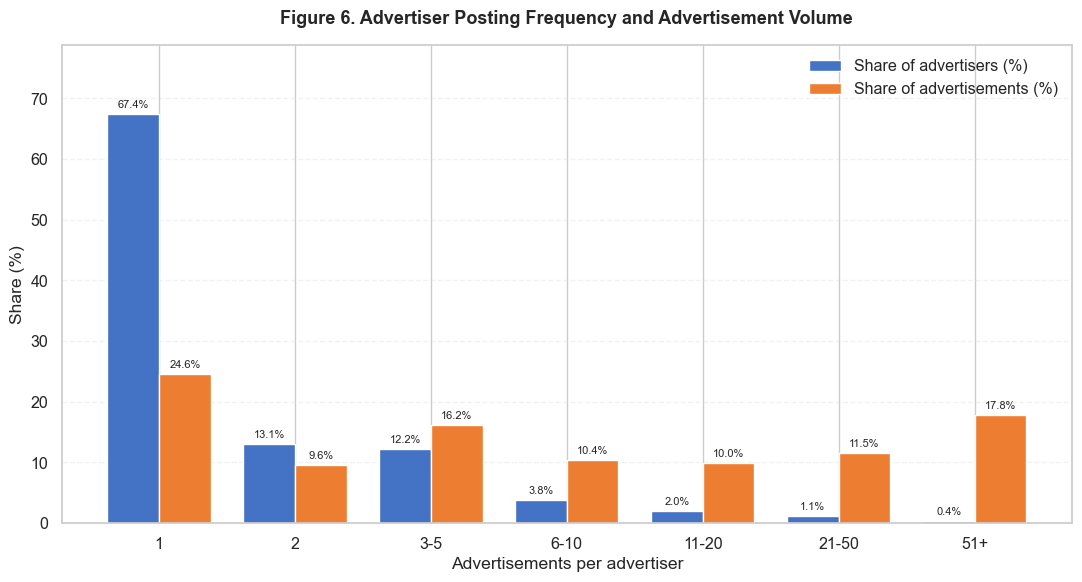


Analysis and Figure 6 saved successfully.


In [25]:

# ============================================================
# RQ2 - STEP 5.4A: ADVERTISER POSTING INTENSITY
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Use the complete advertiser distribution
posting_intensity = advertiser_distribution.copy()

counts = posting_intensity["Advertisements"].astype(int)

total_ads = int(counts.sum())
total_advertisers = len(counts)

assert total_ads == len(rq2_jobs)
assert total_advertisers == 1356

# 2. Distribution statistics
print("=" * 65)
print("RQ2 - ADVERTISER POSTING INTENSITY")
print("=" * 65)

print("Total advertisements:", total_ads)
print("Distinct advertiser labels:", total_advertisers)
print("Mean ads per advertiser:", round(counts.mean(), 2))
print("Median ads per advertiser:", counts.median())
print("Standard deviation:", round(counts.std(), 2))
print("90th percentile:", round(counts.quantile(0.90), 2))
print("95th percentile:", round(counts.quantile(0.95), 2))
print("99th percentile:", round(counts.quantile(0.99), 2))
print("Maximum:", counts.max())

# 3. Non-overlapping posting-frequency bands
posting_intensity["Posting_Band"] = pd.cut(
    posting_intensity["Advertisements"],
    bins=[0, 1, 2, 5, 10, 20, 50, np.inf],
    labels=[
        "1",
        "2",
        "3-5",
        "6-10",
        "11-20",
        "21-50",
        "51+"
    ]
)

band_summary = (
    posting_intensity
    .groupby("Posting_Band", observed=True)
    .agg(
        Advertisers=("company_clean", "count"),
        Advertisements=("Advertisements", "sum")
    )
    .reset_index()
)

band_summary["Advertiser_Share_Pct"] = (
    band_summary["Advertisers"] / total_advertisers * 100
)

band_summary["Advertisement_Share_Pct"] = (
    band_summary["Advertisements"] / total_ads * 100
)

print("\nPOSTING FREQUENCY BANDS:")
display(band_summary.round(2))

# 4. Cumulative threshold analysis
thresholds = [2, 5, 10, 20, 50, 100]

threshold_summary = pd.DataFrame([
    {
        "Minimum_Ads": threshold,
        "Advertisers": int((counts >= threshold).sum()),
        "Advertisements": int(
            counts[counts >= threshold].sum()
        )
    }
    for threshold in thresholds
])

threshold_summary["Advertiser_Share_Pct"] = (
    threshold_summary["Advertisers"]
    / total_advertisers * 100
)

threshold_summary["Advertisement_Share_Pct"] = (
    threshold_summary["Advertisements"]
    / total_ads * 100
)

print("\nCUMULATIVE POSTING THRESHOLDS:")
display(threshold_summary.round(2))

# 5. Figure 6: Advertiser frequency versus advertisement volume
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(band_summary))
width = 0.38

bars1 = ax.bar(
    x - width / 2,
    band_summary["Advertiser_Share_Pct"],
    width,
    label="Share of advertisers (%)",
    color="#4472C4"
)

bars2 = ax.bar(
    x + width / 2,
    band_summary["Advertisement_Share_Pct"],
    width,
    label="Share of advertisements (%)",
    color="#ED7D31"
)

ax.set_xticks(x)
ax.set_xticklabels(band_summary["Posting_Band"].astype(str))

ax.set_xlabel("Advertisements per advertiser")
ax.set_ylabel("Share (%)")

ax.set_title(
    "Figure 6. Advertiser Posting Frequency and "
    "Advertisement Volume",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.legend(frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.1f}%",
            (
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8
        )

ax.set_ylim(
    0,
    max(
        band_summary["Advertiser_Share_Pct"].max(),
        band_summary["Advertisement_Share_Pct"].max()
    ) * 1.17
)

plt.tight_layout()

figure_path = (
    OUTPUT_DIR / "RQ2_Figure_6_Posting_Intensity.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Export results
band_summary.to_csv(
    OUTPUT_DIR / "RQ2_POSTING_FREQUENCY_BANDS.csv",
    index=False
)

threshold_summary.to_csv(
    OUTPUT_DIR / "RQ2_POSTING_INTENSITY_THRESHOLDS.csv",
    index=False
)

print("\nAnalysis and Figure 6 saved successfully.")


In [26]:

# ============================================================
# RQ2 - STEP 5.4B: ADVERTISER CONCENTRATION SENSITIVITY
# ============================================================

import pandas as pd
import numpy as np

# Use the complete advertiser distribution from Step 5.1
base = advertiser_distribution[
    ["company_clean", "Advertisements"]
].copy()

base = base.sort_values(
    "Advertisements", ascending=False
).reset_index(drop=True)

def concentration_metrics(df, scenario):
    counts = df["Advertisements"].to_numpy(dtype=float)
    total = counts.sum()
    shares = counts / total
    sorted_counts = np.sort(counts)
    n = len(counts)

    hhi = np.sum(shares ** 2) * 10000

    gini = (
        2 * np.sum(
            np.arange(1, n + 1) * sorted_counts
        ) / (n * total)
        - (n + 1) / n
    )

    return {
        "Scenario": scenario,
        "Advertisements": int(total),
        "Advertisers": n,
        "CR1_Pct": shares.max() * 100,
        "CR5_Pct": np.sort(shares)[-5:].sum() * 100,
        "CR10_Pct": np.sort(shares)[-10:].sum() * 100,
        "HHI": hhi,
        "Gini": gini,
        "Effective_Advertisers": 1 / np.sum(shares ** 2)
    }

top1 = base.iloc[0]["company_clean"]
top5 = base.head(5)["company_clean"].tolist()

scenarios = [
    concentration_metrics(
        base,
        "All advertisers"
    ),
    concentration_metrics(
        base.loc[base["company_clean"] != top1],
        "Excluding largest advertiser"
    ),
    concentration_metrics(
        base.loc[~base["company_clean"].isin(top5)],
        "Excluding top five advertisers"
    )
]

sensitivity = pd.DataFrame(scenarios)

print("=" * 65)
print("RQ2 - CONCENTRATION SENSITIVITY ANALYSIS")
print("=" * 65)

print("\nLargest advertiser excluded:")
print(top1)

print("\nTop five advertisers excluded:")
for name in top5:
    print("-", name)

print("\nCONCENTRATION COMPARISON:")
display(sensitivity.round(3))

# Changes relative to the complete dataset
baseline = sensitivity.iloc[0]

comparison = sensitivity.copy()

for metric in ["HHI", "Gini", "CR5_Pct"]:
    comparison[f"{metric}_Change"] = (
        comparison[metric] - baseline[metric]
    )

print("\nCHANGES RELATIVE TO BASELINE:")
display(
    comparison[
        [
            "Scenario",
            "Advertisements",
            "HHI_Change",
            "Gini_Change",
            "CR5_Pct_Change"
        ]
    ].round(3)
)

# Validation
assert sensitivity.iloc[0]["Advertisements"] == 3722
assert sensitivity.iloc[0]["Advertisers"] == 1356

# Save results
sensitivity.to_csv(
    OUTPUT_DIR / "RQ2_CONCENTRATION_SENSITIVITY.csv",
    index=False
)

print("\nSensitivity analysis saved successfully.")


RQ2 - CONCENTRATION SENSITIVITY ANALYSIS

Largest advertiser excluded:
LATICRETE International

Top five advertisers excluded:
- LATICRETE International
- Dice
- Tata Consultancy Services
- Stellent IT
- NR Consulting

CONCENTRATION COMPARISON:


,Scenario,Advertisements,Advertisers,CR1_Pct,CR5_Pct,CR10_Pct,HHI,Gini,Effective_Advertisers
0,All advertisers,3722,1356,8.383,17.786,22.730,116.352,0.566,85.946
1,Excluding largest advertiser,3410,1355,4.839,11.554,16.481,54.903,0.527,182.139
2,Excluding top five advertisers,3060,1351,1.438,6.013,10.359,26.857,0.478,372.340



CHANGES RELATIVE TO BASELINE:


,Scenario,Advertisements,HHI_Change,Gini_Change,CR5_Pct_Change
0,All advertisers,3722,0.000,0.000,0.000
1,Excluding largest advertiser,3410,-61.449,-0.039,-6.232
2,Excluding top five advertisers,3060,-89.495,-0.088,-11.773



Sensitivity analysis saved successfully.


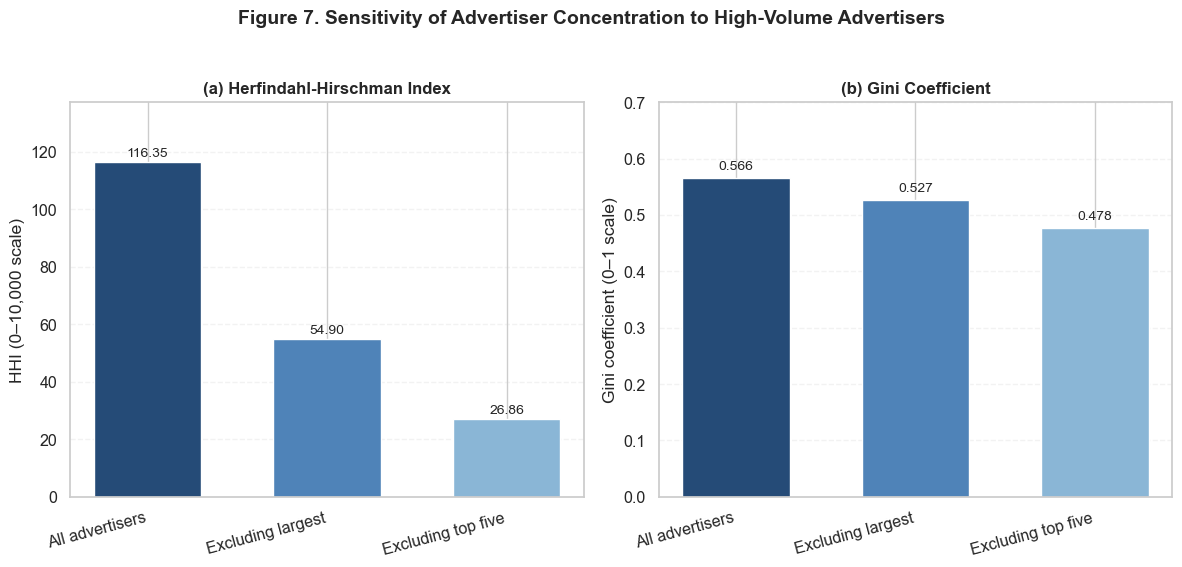

Figure 7 saved: E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis\RQ2_Figure_7_Concentration_Sensitivity.png


In [27]:

# ============================================================
# RQ2 - STEP 5.4C: CONCENTRATION SENSITIVITY FIGURE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

plot_data = sensitivity.copy()

scenario_labels = [
    "All advertisers",
    "Excluding largest",
    "Excluding top five"
]

x = np.arange(len(plot_data))

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5.5)
)

colors = ["#254B77", "#4F83B8", "#8AB6D6"]

# Panel A: HHI
axes[0].bar(
    x, plot_data["HHI"],
    color=colors, width=0.6
)

axes[0].set_title(
    "(a) Herfindahl-Hirschman Index",
    fontsize=12, fontweight="bold"
)
axes[0].set_ylabel("HHI (0–10,000 scale)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(scenario_labels, rotation=15, ha="right")
axes[0].set_ylim(0, plot_data["HHI"].max() * 1.18)
axes[0].grid(axis="y", linestyle="--", alpha=0.25)
axes[0].set_axisbelow(True)

for i, value in enumerate(plot_data["HHI"]):
    axes[0].text(
        i, value + 2, f"{value:.2f}",
        ha="center", fontsize=10
    )

# Panel B: Gini
axes[1].bar(
    x, plot_data["Gini"],
    color=colors, width=0.6
)

axes[1].set_title(
    "(b) Gini Coefficient",
    fontsize=12, fontweight="bold"
)
axes[1].set_ylabel("Gini coefficient (0–1 scale)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(scenario_labels, rotation=15, ha="right")
axes[1].set_ylim(0, 0.7)
axes[1].grid(axis="y", linestyle="--", alpha=0.25)
axes[1].set_axisbelow(True)

for i, value in enumerate(plot_data["Gini"]):
    axes[1].text(
        i, value + 0.015, f"{value:.3f}",
        ha="center", fontsize=10
    )

fig.suptitle(
    "Figure 7. Sensitivity of Advertiser Concentration "
    "to High-Volume Advertisers",
    fontsize=14,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()

figure_path = (
    OUTPUT_DIR / "RQ2_Figure_7_Concentration_Sensitivity.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 7 saved:", figure_path)


In [1]:

import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import spearmanr
from IPython.display import display

# ============================================================
# FINAL QUALITY CHECK 1
# RQ1 LOCATION QUOTIENT SENSITIVITY AFTER DEDUPLICATION
# ============================================================

OUTPUT_DIR = Path(
    r"E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis"
)

# ------------------------------------------------------------
# 1. Load original and deduplicated BA cohorts
# ------------------------------------------------------------

original = pd.read_csv(
    OUTPUT_DIR / "US_BA_GEOGRAPHY.csv"
)

dedup = pd.read_csv(
    OUTPUT_DIR / "FINAL_BA_STRICT_DEDUP_COHORT.csv"
)

# ------------------------------------------------------------
# 2. Find existing labour-force dataset
# ------------------------------------------------------------

print("Available CSV files containing labour-force information:")

candidate_files = [
    p for p in OUTPUT_DIR.glob("*.csv")
    if any(
        term in p.name.lower()
        for term in ["labour", "labor", "workforce", "rq1_state"]
    )
]

for path in candidate_files:
    print("-", path.name)

# Reuse the original RQ1 state analysis if available
rq1_path = OUTPUT_DIR / "RQ1_STATE_ANALYSIS.csv"

if rq1_path.exists():
    state_reference = pd.read_csv(rq1_path)
else:
    raise FileNotFoundError(
        "RQ1_STATE_ANALYSIS.csv not found. "
        "Please share the available filenames printed above "
        "so we can use your original labour-force data."
    )

print("\nRQ1 state reference columns:")
print(state_reference.columns.tolist())

display(state_reference.head())

# ------------------------------------------------------------
# 3. Validate reference structure
# ------------------------------------------------------------

# Identify column names used in the original RQ1 analysis
state_candidates = ["state_clean", "State", "state"]
labour_candidates = [
    "Labour_Force",
    "Labor_Force",
    "labour_force",
    "labor_force",
    "Civilian_Labor_Force"
]

state_col = next(
    (c for c in state_candidates if c in state_reference.columns),
    None
)

labour_col = next(
    (c for c in labour_candidates if c in state_reference.columns),
    None
)

if state_col is None or labour_col is None:
    raise ValueError(
        "Could not automatically identify state or labour-force "
        "columns. Please share the displayed column names."
    )

# ------------------------------------------------------------
# 4. Prepare state reference
# ------------------------------------------------------------

reference = state_reference[
    [state_col, labour_col]
].copy()

reference.columns = [
    "state_clean",
    "Labour_Force"
]

reference["Labour_Force"] = pd.to_numeric(
    reference["Labour_Force"],
    errors="coerce"
)

reference = reference.dropna(
    subset=["state_clean", "Labour_Force"]
)

reference = reference.drop_duplicates(
    subset=["state_clean"]
)

# ------------------------------------------------------------
# 5. Calculate location quotients
# ------------------------------------------------------------

def calculate_lq(df, reference):

    counts = (
        df.groupby("state_clean")["job_link"]
        .nunique()
    )

    result = reference.copy()

    result["Advertisements"] = (
        result["state_clean"]
        .map(counts)
        .fillna(0)
    )

    total_ads = result["Advertisements"].sum()
    total_labour = result["Labour_Force"].sum()

    result["Ad_Share"] = (
        result["Advertisements"] / total_ads
    )

    result["Labour_Share"] = (
        result["Labour_Force"] / total_labour
    )

    result["LQ"] = (
        result["Ad_Share"] / result["Labour_Share"]
    )

    return result

original_lq = calculate_lq(original, reference)
dedup_lq = calculate_lq(dedup, reference)

# ------------------------------------------------------------
# 6. Compare original and deduplicated LQs
# ------------------------------------------------------------

comparison = original_lq[
    ["state_clean", "Advertisements", "LQ"]
].merge(
    dedup_lq[
        ["state_clean", "Advertisements", "LQ"]
    ],
    on="state_clean",
    suffixes=("_Original", "_Dedup")
)

comparison["LQ_Change"] = (
    comparison["LQ_Dedup"]
    - comparison["LQ_Original"]
)

comparison["LQ_Change_Pct"] = np.where(
    comparison["LQ_Original"] > 0,
    comparison["LQ_Change"]
    / comparison["LQ_Original"] * 100,
    np.nan
)

# ------------------------------------------------------------
# 7. Compare rankings and correlations
# ------------------------------------------------------------

comparison["Rank_Original"] = (
    comparison["LQ_Original"]
    .rank(ascending=False, method="min")
)

comparison["Rank_Dedup"] = (
    comparison["LQ_Dedup"]
    .rank(ascending=False, method="min")
)

rho, p_value = spearmanr(
    comparison["LQ_Original"],
    comparison["LQ_Dedup"]
)

print("\n" + "=" * 65)
print("RQ1 - LOCATION QUOTIENT DEDUPLICATION ROBUSTNESS")
print("=" * 65)

print("Original BA advertisements:", len(original))
print("Deduplicated BA advertisements:", len(dedup))

print("\nState-identified advertisements:")
print("Original:", int(original_lq["Advertisements"].sum()))
print("Deduplicated:", int(dedup_lq["Advertisements"].sum()))

print("\nSpearman correlation between LQ rankings:")
print("Rho:", round(rho, 4))
print("P-value:", p_value)

print("\nTOP 15 STATES BY ORIGINAL LOCATION QUOTIENT:")

display(
    comparison.sort_values(
        "LQ_Original",
        ascending=False
    ).head(15).round(3)
)

print("\nLARGEST ABSOLUTE LQ CHANGES:")

display(
    comparison.assign(
        Absolute_Change=comparison["LQ_Change"].abs()
    )
    .sort_values(
        "Absolute_Change",
        ascending=False
    )
    .head(15)
    .round(3)
)

# ------------------------------------------------------------
# 8. Save
# ------------------------------------------------------------

comparison.to_csv(
    OUTPUT_DIR / "FINAL_RQ1_LQ_DEDUP_ROBUSTNESS.csv",
    index=False
)

print("\nRQ1 LQ sensitivity analysis saved successfully.")


C:\Users\Dell\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\Dell\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Available CSV files containing labour-force information:
- BLS_JAN2024_LABOUR_FORCE_CLEAN.csv
- RQ1_STATE_DISTRIBUTION.csv
- RQ1_WORKFORCE_ADJUSTED.csv


FileNotFoundError: RQ1_STATE_ANALYSIS.csv not found. Please share the available filenames printed above so we can use your original labour-force data.

In [2]:

import pandas as pd
from pathlib import Path
from IPython.display import display

OUTPUT_DIR = Path(
    r"E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis"
)

files = [
    "BLS_JAN2024_LABOUR_FORCE_CLEAN.csv",
    "RQ1_STATE_DISTRIBUTION.csv",
    "RQ1_WORKFORCE_ADJUSTED.csv"
]

for filename in files:
    path = OUTPUT_DIR / filename

    print("\n" + "=" * 65)
    print("FILE:", filename)
    print("=" * 65)

    if path.exists():
        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        display(df.head(5))
    else:
        print("File not found")



FILE: BLS_JAN2024_LABOUR_FORCE_CLEAN.csv
Shape: (51, 3)
Columns: ['State_Name', 'Labour_Force', 'State']


,State_Name,Labour_Force,State
0,Alabama,2327861,AL
1,Alaska,358278,AK
2,Arizona,3726618,AZ
3,Arkansas,1385260,AR
4,California,19357440,CA



FILE: RQ1_STATE_DISTRIBUTION.csv
Shape: (50, 4)
Columns: ['State', 'Advertisements', 'Share (%)', 'Cumulative Share (%)']


,State,Advertisements,Share (%),Cumulative Share (%)
0,TX,341,9.20,9.20
1,CA,339,9.14,18.34
2,FL,279,7.52,25.86
3,NY,255,6.88,32.74
4,NJ,205,5.53,38.27



FILE: RQ1_WORKFORCE_ADJUSTED.csv
Shape: (51, 8)
Columns: ['State_Name', 'Labour_Force', 'State', 'Advertisements', 'Ad_Share_Pct', 'Labour_Force_Share_Pct', 'Ads_per_100k', 'Location_Quotient']


,State_Name,Labour_Force,State,Advertisements,Ad_Share_Pct,Labour_Force_Share_Pct,Ads_per_100k,Location_Quotient
0,Alabama,2327861,AL,28,0.755124,1.391084,1.202821,0.542831
1,Alaska,358278,AK,4,0.107875,0.214100,1.116451,0.503853
2,Arizona,3726618,AZ,46,1.240561,2.226954,1.234363,0.557066
3,Arkansas,1385260,AR,22,0.593312,0.827804,1.588150,0.716730
4,California,19357440,CA,339,9.142395,11.567625,1.751265,0.790343


In [3]:

import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import spearmanr
from IPython.display import display

# ============================================================
# FINAL QUALITY CHECK 1
# RQ1 LOCATION QUOTIENT SENSITIVITY AFTER DEDUPLICATION
# ============================================================

OUTPUT_DIR = Path(
    r"E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis"
)

# ------------------------------------------------------------
# 1. Load existing datasets
# ------------------------------------------------------------

original = pd.read_csv(
    OUTPUT_DIR / "US_BA_GEOGRAPHY.csv"
)

dedup = pd.read_csv(
    OUTPUT_DIR / "FINAL_BA_STRICT_DEDUP_COHORT.csv"
)

reference = pd.read_csv(
    OUTPUT_DIR / "RQ1_WORKFORCE_ADJUSTED.csv"
)

# ------------------------------------------------------------
# 2. Validate original reference
# ------------------------------------------------------------

required_cols = [
    "State",
    "Labour_Force",
    "Advertisements",
    "Location_Quotient"
]

missing = [
    c for c in required_cols
    if c not in reference.columns
]

if missing:
    raise ValueError(
        f"Missing reference columns: {missing}"
    )

assert reference["State"].nunique() == 51
assert original["job_link"].nunique() == 3722
assert dedup["job_link"].nunique() == 3368

reference["State"] = (
    reference["State"].astype(str).str.strip().str.upper()
)

reference["Labour_Force"] = pd.to_numeric(
    reference["Labour_Force"],
    errors="raise"
)

assert reference["Labour_Force"].gt(0).all()

# ------------------------------------------------------------
# 3. Calculate LQ using the same workforce denominator
# ------------------------------------------------------------

def calculate_lq(df, ref):

    counts = (
        df.dropna(subset=["state_clean"])
        .groupby("state_clean")["job_link"]
        .nunique()
    )

    result = ref[
        ["State", "Labour_Force"]
    ].copy()

    result["Advertisements"] = (
        result["State"]
        .map(counts)
        .fillna(0)
        .astype(int)
    )

    total_ads = result["Advertisements"].sum()
    total_workforce = result["Labour_Force"].sum()

    result["Ad_Share"] = (
        result["Advertisements"] / total_ads
    )

    result["Workforce_Share"] = (
        result["Labour_Force"] / total_workforce
    )

    result["Location_Quotient"] = (
        result["Ad_Share"]
        / result["Workforce_Share"]
    )

    return result

original_calc = calculate_lq(original, reference)
dedup_calc = calculate_lq(dedup, reference)

# ------------------------------------------------------------
# 4. Verify the original calculation matches saved RQ1
# ------------------------------------------------------------

validation = original_calc.merge(
    reference[
        ["State", "Advertisements", "Location_Quotient"]
    ],
    on="State",
    suffixes=("_Recalculated", "_Saved")
)

assert (
    validation["Advertisements_Recalculated"]
    == validation["Advertisements_Saved"]
).all(), "Original advertisement counts do not match saved RQ1."

assert np.allclose(
    validation["Location_Quotient_Recalculated"],
    validation["Location_Quotient_Saved"],
    atol=1e-5
), "Original location quotients do not match saved RQ1."

print("Original RQ1 counts and LQs successfully validated.")

# ------------------------------------------------------------
# 5. Compare original and deduplicated results
# ------------------------------------------------------------

comparison = original_calc[
    ["State", "Advertisements", "Location_Quotient"]
].merge(
    dedup_calc[
        ["State", "Advertisements", "Location_Quotient"]
    ],
    on="State",
    suffixes=("_Original", "_Dedup")
)

comparison["LQ_Change"] = (
    comparison["Location_Quotient_Dedup"]
    - comparison["Location_Quotient_Original"]
)

comparison["LQ_Change_Pct"] = np.where(
    comparison["Location_Quotient_Original"] > 0,
    comparison["LQ_Change"]
    / comparison["Location_Quotient_Original"] * 100,
    np.nan
)

comparison["Rank_Original"] = (
    comparison["Location_Quotient_Original"]
    .rank(ascending=False, method="min")
)

comparison["Rank_Dedup"] = (
    comparison["Location_Quotient_Dedup"]
    .rank(ascending=False, method="min")
)

comparison["Rank_Change"] = (
    comparison["Rank_Dedup"]
    - comparison["Rank_Original"]
)

# ------------------------------------------------------------
# 6. Calculate ranking correlation
# ------------------------------------------------------------

rho, p_value = spearmanr(
    comparison["Location_Quotient_Original"],
    comparison["Location_Quotient_Dedup"]
)

# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("RQ1 - DEDUPLICATED LOCATION QUOTIENT ROBUSTNESS")
print("=" * 65)

print("\nORIGINAL COHORT")
print("Total advertisements:", len(original))
print(
    "State-identified:",
    original_calc["Advertisements"].sum()
)

print("\nDEDUPLICATED COHORT")
print("Total advertisements:", len(dedup))
print(
    "State-identified:",
    dedup_calc["Advertisements"].sum()
)

print("\nSPEARMAN RANK CORRELATION")
print("Rho:", round(rho, 4))
print("P-value:", p_value)

print("\nTOP 15 STATES BY ORIGINAL LOCATION QUOTIENT")

display(
    comparison.sort_values(
        "Location_Quotient_Original",
        ascending=False
    ).head(15).round(3)
)

print("\nTOP 15 STATES BY DEDUPLICATED LOCATION QUOTIENT")

display(
    comparison.sort_values(
        "Location_Quotient_Dedup",
        ascending=False
    ).head(15).round(3)
)

print("\nLARGEST ABSOLUTE LOCATION QUOTIENT CHANGES")

display(
    comparison.assign(
        Absolute_Change=comparison["LQ_Change"].abs()
    )
    .sort_values(
        "Absolute_Change",
        ascending=False
    )
    .head(15)
    .round(3)
)

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

comparison.to_csv(
    OUTPUT_DIR / "FINAL_RQ1_LQ_DEDUP_ROBUSTNESS.csv",
    index=False
)

print("\nRQ1 LQ robustness results saved successfully.")


Original RQ1 counts and LQs successfully validated.

RQ1 - DEDUPLICATED LOCATION QUOTIENT ROBUSTNESS

ORIGINAL COHORT
Total advertisements: 3722
State-identified: 3708

DEDUPLICATED COHORT
Total advertisements: 3368
State-identified: 3355

SPEARMAN RANK CORRELATION
Rho: 0.9897
P-value: 5.13986354009756e-43

TOP 15 STATES BY ORIGINAL LOCATION QUOTIENT


,State,Advertisements_Original,Location_Quotient_Original,Advertisements_Dedup,Location_Quotient_Dedup,LQ_Change,LQ_Change_Pct,Rank_Original,Rank_Dedup,Rank_Change
8,DC,59,6.599,56,6.923,0.323,4.902,1.0,1.0,0.0
21,MA,165,1.986,137,1.822,-0.163,-8.234,2.0,3.0,1.0
30,NJ,205,1.918,192,1.985,0.067,3.513,3.0,2.0,-1.0
46,VA,180,1.770,158,1.718,-0.053,-2.987,4.0,4.0,0.0
39,RI,19,1.482,19,1.638,0.156,10.522,5.0,5.0,0.0
33,NC,158,1.357,146,1.386,0.029,2.128,6.0,6.0,0.0
10,GA,157,1.329,138,1.291,-0.038,-2.854,7.0,7.0,0.0
6,CT,55,1.305,47,1.232,-0.072,-5.554,8.0,9.0,1.0
20,MD,92,1.300,82,1.281,-0.019,-1.492,9.0,8.0,-1.0
32,NY,255,1.180,235,1.202,0.022,1.853,10.0,10.0,0.0



TOP 15 STATES BY DEDUPLICATED LOCATION QUOTIENT


,State,Advertisements_Original,Location_Quotient_Original,Advertisements_Dedup,Location_Quotient_Dedup,LQ_Change,LQ_Change_Pct,Rank_Original,Rank_Dedup,Rank_Change
8,DC,59,6.599,56,6.923,0.323,4.902,1.0,1.0,0.0
30,NJ,205,1.918,192,1.985,0.067,3.513,3.0,2.0,-1.0
21,MA,165,1.986,137,1.822,-0.163,-8.234,2.0,3.0,1.0
46,VA,180,1.770,158,1.718,-0.053,-2.987,4.0,4.0,0.0
39,RI,19,1.482,19,1.638,0.156,10.522,5.0,5.0,0.0
33,NC,158,1.357,146,1.386,0.029,2.128,6.0,6.0,0.0
10,GA,157,1.329,138,1.291,-0.038,-2.854,7.0,7.0,0.0
20,MD,92,1.300,82,1.281,-0.019,-1.492,9.0,8.0,-1.0
6,CT,55,1.305,47,1.232,-0.072,-5.554,8.0,9.0,1.0
32,NY,255,1.180,235,1.202,0.022,1.853,10.0,10.0,0.0



LARGEST ABSOLUTE LOCATION QUOTIENT CHANGES


,State,Advertisements_Original,Location_Quotient_Original,Advertisements_Dedup,Location_Quotient_Dedup,LQ_Change,LQ_Change_Pct,Rank_Original,Rank_Dedup,Rank_Change,Absolute_Change
8,DC,59,6.599,56,6.923,0.323,4.902,1.0,1.0,0.0,0.323
3,AR,22,0.717,15,0.540,-0.177,-24.644,30.0,36.0,6.0,0.177
27,NE,25,1.069,19,0.898,-0.171,-16.004,15.0,20.0,5.0,0.171
21,MA,165,1.986,137,1.822,-0.163,-8.234,2.0,3.0,1.0,0.163
39,RI,19,1.482,19,1.638,0.156,10.522,5.0,5.0,0.0,0.156
49,WI,75,1.075,74,1.173,0.097,9.048,14.0,13.0,-1.0,0.097
45,VT,4,0.510,3,0.423,-0.087,-17.109,38.0,43.0,5.0,0.087
35,OH,131,1.020,109,0.938,-0.082,-8.039,17.0,19.0,2.0,0.082
6,CT,55,1.305,47,1.232,-0.072,-5.554,8.0,9.0,1.0,0.072
0,AL,28,0.543,22,0.471,-0.071,-13.162,36.0,40.0,4.0,0.071



RQ1 LQ robustness results saved successfully.


In [4]:

import pandas as pd
from pathlib import Path
from IPython.display import display

OUTPUT_DIR = Path(
    r"E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis"
)

ba = pd.read_csv(
    OUTPUT_DIR / "FINAL_BA_REPOST_FLAGS.csv"
)

keys = ["company_norm", "title_norm", "location_norm"]

valid = ba[keys].fillna("").ne("").all(axis=1)

groups = (
    ba.loc[valid]
    .groupby(keys)
    .size()
    .reset_index(name="Group_Size")
)

groups = groups[groups["Group_Size"] > 1].copy()

# Five largest groups
largest = groups.nlargest(5, "Group_Size")

# Five randomly selected other groups
remaining = groups.drop(largest.index)
random_groups = remaining.sample(
    n=min(5, len(remaining)),
    random_state=42
)

# Five further groups from advertisers not already sampled
selected = pd.concat([largest, random_groups])
other = remaining.drop(random_groups.index)

other = other[
    ~other["company_norm"].isin(selected["company_norm"])
]

additional = other.sample(
    n=min(5, len(other)),
    random_state=24
)

selected = pd.concat(
    [selected, additional],
    ignore_index=True
)

selected["Review_Group"] = range(1, len(selected) + 1)

review = ba.merge(
    selected[keys + ["Review_Group", "Group_Size"]],
    on=keys,
    how="inner"
)

review = review.sort_values(
    ["Review_Group", "first_seen", "job_link"]
)

review["Reviewer_Classification"] = ""
review["Reviewer_Notes"] = ""

columns = [
    "Review_Group",
    "Group_Size",
    "company",
    "job_title",
    "job_location",
    "first_seen",
    "job_link",
    "Reviewer_Classification",
    "Reviewer_Notes"
]

review = review[columns]

path = OUTPUT_DIR / "FINAL_MANUAL_REPOST_REVIEW.csv"
review.to_csv(path, index=False)

print("Groups selected:", review["Review_Group"].nunique())
print("Advertisements selected:", len(review))
print("Review file:", path)

display(
    review.groupby(
        ["Review_Group", "company", "job_title", "job_location"],
        dropna=False
    ).agg(
        Advertisements=("job_link", "size"),
        Distinct_Dates=("first_seen", "nunique")
    ).reset_index()
)


Groups selected: 15
Advertisements selected: 70
Review file: E:\Analytic Plan BI\LinkedIn Dataset\Assignment_2_Analysis\FINAL_MANUAL_REPOST_REVIEW.csv


,Review_Group,company,job_title,job_location,Advertisements,Distinct_Dates
0,1,LATICRETE International,JD Edwards Business Analyst,"California, United States",11,1
1,2,LATICRETE International,JDE Business Analyst (Supply Chain),"Texas, United States",9,1
2,3,Tata Consultancy Services,Business Analyst,"Boston, MA",9,2
3,4,Hexaware Technologies,ERP Fin Business Analyst,"Perrysburg, OH",8,2
4,5,LATICRETE International,JD Edwards Business Analyst,"Texas, United States",8,1
5,6,ATC,Business Analyst II,"Clive, IA",2,1
6,7,Stellent IT,Business Analyst,"Atlanta, GA",3,2
7,8,LATICRETE International,JDE Business Analyst (Supply Chain),"North Carolina, United States",3,1
8,9,Tata Consultancy Services,Business Analyst,"Tampa, FL",3,1
9,10,OSO Ventures Inc,Business Analyst,"Washington, DC",3,1
